# Data Mining — Practice 1
## Data Preprocessing: Aggregation, Sampling, Feature Subset Selection, Feature Creation

**Dataset:** Hotel Booking Demand — **https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand**
(file `hotel_bookings.csv`, original source: Antonio, Almeida & Nunes, *Hotel booking demand datasets*, Data in Brief, 2019)

| Property | Value |
|---|---|
| Rows | 119,390 bookings |
| Attributes | 32 (20 numeric, 12 categorical) |
| Period | arrivals from July 2015 to August 2017 |
| Hotels | City Hotel (Lisbon) and Resort Hotel (Algarve), Portugal |
| **Target / label** | **`is_canceled`** — 1 if the booking was cancelled, 0 otherwise (binary classification) |

Key attributes used below: `adr` (Average Daily Rate = price per room-night), `lead_time` (days between booking and arrival),
`stays_in_weekend_nights` / `stays_in_week_nights`, `market_segment`, `customer_type`, `deposit_type`, `country`,
`previous_cancellations`, `total_of_special_requests`, arrival date parts (`arrival_date_year`, `arrival_date_month`, `arrival_date_day_of_month`).

> The notebook must be run top-to-bottom (`Restart & Run All`). `hotel_bookings.csv` must be in the same folder. All randomness is controlled by `SEED = 42`.

In [1]:
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sklearn
import statsmodels
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif, RFECV, RFE
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

%matplotlib inline
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', '{:,.3f}'.format)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__,
      '| statsmodels', statsmodels.__version__)

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | statsmodels 0.15.0


## 0. Loading and cleaning the data

In [2]:
raw = pd.read_csv('hotel_bookings.csv')
n_numeric = raw.select_dtypes(include='number').shape[1]
print('Shape:', raw.shape)
print(f'Numeric attributes: {n_numeric}, categorical attributes: {raw.shape[1] - n_numeric}')
display(raw.head())

missing = raw.isna().sum()
missing = missing[missing > 0].to_frame('n_missing')
missing['pct_missing'] = 100 * missing['n_missing'] / len(raw)
display(missing)

print('Target distribution (is_canceled):')
print(raw['is_canceled'].value_counts(normalize=True).rename('share'))

Shape: (119390, 32)
Numeric attributes: 20, categorical attributes: 12


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,2015-07-03


,n_missing,pct_missing
children,4,0.003
country,488,0.409
agent,16340,13.686
company,112593,94.307


Target distribution (is_canceled):
is_canceled
0   0.630
1   0.370
Name: share, dtype: float64


In [3]:
df = raw.copy()

# 1) Remove target leakage.
#    reservation_status ('Canceled' / 'No-Show' / 'Check-Out') is the target written in another form,
#    reservation_status_date is recorded AFTER the outcome, assigned_room_type is only decided at check-in.
df = df.drop(columns=['reservation_status', 'reservation_status_date', 'assigned_room_type'])

# 2) Missing values
df['children'] = df['children'].fillna(0).astype(int)          # 4 missing -> 0 children
df['country'] = df['country'].fillna('Unknown')                 # 488 missing -> own category
df['has_agent'] = df['agent'].notna().astype(int)               # agent / company are IDs with 13.7% / 94.3% missing:
df['has_company'] = df['company'].notna().astype(int)           # keep only the information "booked via agent / company"
df = df.drop(columns=['agent', 'company'])

# 3) Invalid records: bookings with 0 guests, negative ADR, one extreme ADR outlier (5400 vs. 75th pct. 126)
guests = df['adults'] + df['children'] + df['babies']
invalid = (guests == 0) | (df['adr'] < 0) | (df['adr'] > 1000)
print('Invalid rows removed:', int(invalid.sum()))
df = df.loc[~invalid].reset_index(drop=True)

# 4) Helper columns used throughout the notebook
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
df['arrival_month'] = df['arrival_date_month'].map({m: i for i, m in enumerate(MONTHS, start=1)})
df['arrival_date'] = pd.to_datetime(pd.DataFrame({'year': df['arrival_date_year'],
                                                  'month': df['arrival_month'],
                                                  'day': df['arrival_date_day_of_month']}))
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

N = len(df)
print('Clean shape:', df.shape)
print('Arrival dates:', df['arrival_date'].min().date(), '->', df['arrival_date'].max().date())
print('Cancellation rate:', round(df['is_canceled'].mean(), 4))

Invalid rows removed: 182
Clean shape: (119208, 32)
Arrival dates: 2015-07-01 -> 2017-08-31
Cancellation rate: 0.3708


**Cleaning decisions.** Three columns were removed because they leak the target: `reservation_status` literally encodes whether the booking was cancelled, and its date as well as `assigned_room_type` are only known after the outcome — a model using them would look perfect but be useless at booking time. `agent`/`company` are high-cardinality IDs with many missing values, so they were replaced by binary indicators. Rows with zero guests, negative ADR, or the single ADR = 5400 outlier are data-entry errors and were removed.

---
# Part 1. Aggregation

## Task 1.1 — Multi-level aggregation (`market_segment` × `customer_type`, statistic of `adr`)

`market_segment` is the primary category (how the booking was sold: Online TA, Groups, Direct, …) and `customer_type` is the secondary category (Transient, Transient-Party, Contract, Group). The numeric attribute is `adr`.

In [4]:
def IQR(x):
    """Interquartile range: Q3 - Q1 (robust measure of spread)."""
    return x.quantile(0.75) - x.quantile(0.25)

# Long format: one row per (market_segment, customer_type) group
long_agg = (df.groupby(['market_segment', 'customer_type'])['adr']
              .agg(n='count', mean='mean', median='median', std='std', IQR=IQR))
print('Long (MultiIndex) aggregation, first 10 groups:')
display(long_agg.head(10).round(2))

Long (MultiIndex) aggregation, first 10 groups:


n    mean  median    std    IQR
market_segment customer_type                                      
Aviation       Group               2 110.000 110.000  0.000  0.000
               Transient         216 101.100  95.000 20.570 15.000
               Transient-Party    17  98.530  95.000  6.560  0.000
Complementary  Contract            2   4.200   4.200  2.550  1.800
               Group               6  13.170   0.000 32.250  0.000
               Transient         688   2.400   0.000 13.090  0.000
               Transient-Party    32  12.690   0.000 24.990  4.000
Corporate      Contract           22  49.750  46.500  9.980  5.000
               Group              28  86.220  65.000 64.770 23.500
               Transient        3569  68.010  65.000 31.890 42.000

In [5]:
# (a) Wide-format pivot table: rows = primary category, columns = (statistic, secondary category)
pivot = pd.pivot_table(df, index='market_segment', columns='customer_type', values='adr',
                       aggfunc=['count', 'mean', 'median', 'std', IQR])
pivot.round(1)

count                                        mean                                     median                                        std                                       IQR                   \
customer_type   Contract   Group  Transient Transient-Party Contract   Group Transient Transient-Party Contract   Group Transient Transient-Party Contract  Group Transient Transient-Party Contract  Group Transient   
market_segment                                                                                                                                                                                                          
Aviation             NaN   2.000    216.000          17.000      NaN 110.000   101.100          98.500      NaN 110.000    95.000          95.000      NaN  0.000    20.600           6.600      NaN  0.000    15.000   
Complementary      2.000   6.000    688.000          32.000    4.200  13.200     2.400          12.700    4.200   0.000     0.000           0.000    2.500 32.300    13.100          25.000    1.800  0.000     0.000   
Corporate         22.000  28.000  3,569.000       1,663.000   49.800  86.200    68.000          72.800   46.500  65.000    65.000          75.000   10.000 64.800    31.900          30.000    5.000 23.500    42.000   
Direct            14.000 134.000 11,317.000       1,117.000   59.300  97.600   116.800         106.200   53.000  93.500   107.100          95.400   16.400 58.400    59.700          51.700   17.200 67.200    76.500   
Groups           735.000  16.000  8,423.000      10,616.000   62.700  55.600    86.700          75.100   62.000  69.200    80.000          67.000    5.400 29.400    33.000          31.800    0.000 21.200    38.000   
Offline TA/TO  1,816.000 210.000 14,026.000       8,129.000   80.000  75.600    85.400          92.400   72.900  63.400    83.300          94.500   32.700 44.700    34.900          30.100   44.400 44.400    40.000   
Online TA      1,483.000 178.000 51,236.000       3,511.000  110.300  87.700   118.400         106.100  105.000  85.000   111.400          99.400   29.000 44.100    49.300          45.900   33.000 52.100    58.500   
Undefined            NaN     NaN        NaN           2.000      NaN     NaN       NaN          15.000      NaN     NaN       NaN          15.000      NaN    NaN       NaN           4.200      NaN    NaN       NaN   

                                
customer_type  Transient-Party  
market_segment                  
Aviation                 0.000  
Complementary            4.000  
Corporate               42.000  
Direct                  55.000  
Groups                  24.000  
Offline TA/TO           35.800  
Online TA               50.400  
Undefined                3.000

In [6]:
# (b) Flag groups with fewer than 30 observations
MIN_N = 30
long_agg['SE_mean'] = long_agg['std'] / np.sqrt(long_agg['n'])                        # standard error of the mean
long_agg['CI95_half_width'] = stats.t.ppf(0.975, long_agg['n'] - 1) * long_agg['SE_mean']
long_agg['flag_n_lt_30'] = long_agg['n'] < MIN_N

flagged = long_agg[long_agg['flag_n_lt_30']]
reliable = long_agg[~long_agg['flag_n_lt_30']]
print(f'{len(flagged)} of {len(long_agg)} groups have fewer than {MIN_N} observations:')
display(flagged.round(2))
print(f'Median 95% CI half-width of the mean — groups with n >= 30: {reliable["CI95_half_width"].median():.2f}, '
      f'groups with n < 30: {flagged["CI95_half_width"].median():.2f}')

9 of 28 groups have fewer than 30 observations:


n    mean  median    std    IQR  SE_mean  CI95_half_width  flag_n_lt_30
market_segment customer_type                                                                            
Aviation       Group             2 110.000 110.000  0.000  0.000    0.000            0.000          True
               Transient-Party  17  98.530  95.000  6.560  0.000    1.590            3.370          True
Complementary  Contract          2   4.200   4.200  2.550  1.800    1.800           22.870          True
               Group             6  13.170   0.000 32.250  0.000   13.170           33.850          True
Corporate      Contract         22  49.750  46.500  9.980  5.000    2.130            4.420          True
               Group            28  86.220  65.000 64.770 23.500   12.240           25.120          True
Direct         Contract         14  59.290  53.000 16.410 17.250    4.390            9.480          True
Groups         Group            16  55.600  69.160 29.380 21.250    7.340           15.650          True
Undefined      Transient-Party   2  15.000  15.000  4.240  3.000    3.000           38.120          True

Median 95% CI half-width of the mean — groups with n >= 30: 1.44, groups with n < 30: 15.65


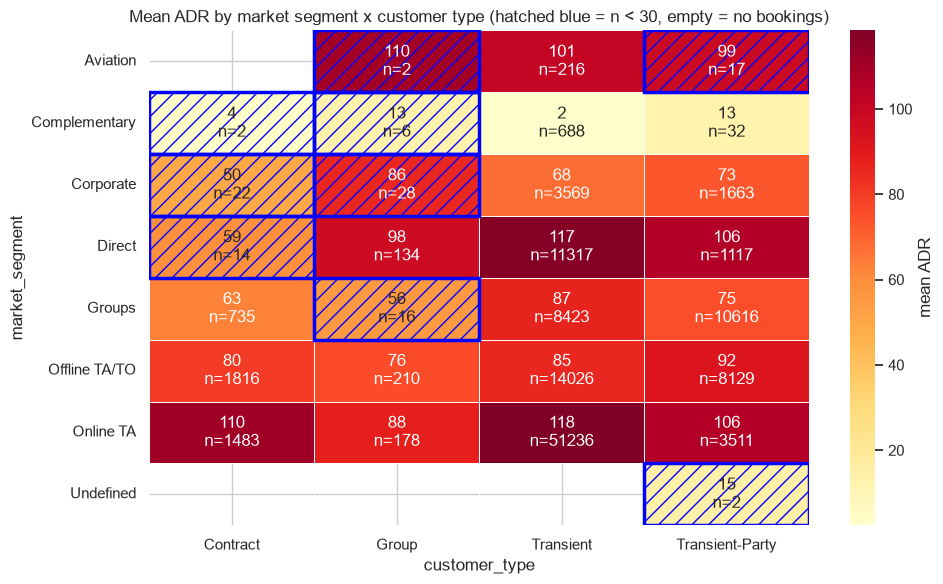

In [7]:
mean_tbl = pivot['mean']
n_tbl = pivot['count'].reindex_like(mean_tbl).fillna(0).astype(int)

labels = np.empty(mean_tbl.shape, dtype=object)
for i, seg in enumerate(mean_tbl.index):
    for j, ct in enumerate(mean_tbl.columns):
        n = n_tbl.loc[seg, ct]
        labels[i, j] = '' if n == 0 else f'{mean_tbl.loc[seg, ct]:.0f}\nn={n}'

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(mean_tbl, annot=labels, fmt='', cmap='YlOrRd', linewidths=0.5, ax=ax,
            cbar_kws={'label': 'mean ADR'})
for i, seg in enumerate(mean_tbl.index):
    for j, ct in enumerate(mean_tbl.columns):
        if 0 < n_tbl.loc[seg, ct] < MIN_N:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='blue', lw=2.5, hatch='//'))
ax.set_title('Mean ADR by market segment x customer type (hatched blue = n < 30, empty = no bookings)')
plt.tight_layout()
plt.show()

**Interpretation 1.1.** The pivot table shows that price depends on both levels at once. Transient guests from Online TA pay the most (mean ADR 118.4, n = 51,236), while *Complementary* bookings are essentially free rooms (mean ADR 2–13). **9 of the 28 non-empty groups have fewer than 30 bookings** (hatched cells). Their statistics are unreliable: the median 95% CI half-width of the mean is **±15.65** for these groups vs **±1.44** for groups with n ≥ 30. For example, *Corporate × Group* (n = 28) has mean 86.2 but median 65.0 and std 64.8, so a single expensive booking moves the mean by several units. *Aviation × Group* (n = 2) shows std = 0, which does not mean prices are stable — two observations simply cannot estimate spread. With n < 30 the sampling distribution of the mean cannot be assumed normal (CLT rule of thumb) and outliers dominate, so these cells should not be compared with the large groups or used as stable group-level features (Task 4.4 replaces them with the hotel-level value).

## Task 1.2 — Weighted aggregation: ADR weighted by length of stay

`adr` is a price **per room-night**. A 1-night booking and a 14-night booking contribute equally to the plain mean, although the second one generates 14× more room-nights. The revenue-relevant "average price per sold room-night" must therefore be weighted by `total_nights`. Only realised stays are used (`is_canceled = 0`, `total_nights > 0`), because cancelled bookings produced no room-nights.

In [8]:
def unweighted_mean(x):
    # x̄ = Σ_i x_i / n
    x = np.asarray(x, dtype=float)
    return np.sum(x) / len(x)


def weighted_mean(x, w):
    # x̄_w = Σ_i (w_i · x_i) / Σ_i w_i        (x_i = ADR of booking i, w_i = nights of booking i)
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)
    return np.sum(w * x) / np.sum(w)


stays = df[(df['is_canceled'] == 0) & (df['total_nights'] > 0)]
rows = []
for seg, g in stays.groupby('market_segment'):
    x, w = g['adr'].to_numpy(), g['total_nights'].to_numpy()
    mu, mu_w = unweighted_mean(x), weighted_mean(x, w)
    rows.append({
        'market_segment': seg, 'n_bookings': len(g), 'room_nights': int(w.sum()), 'avg_nights': w.mean(),
        'unweighted_ADR': mu, 'weighted_ADR': mu_w,
        'diff': mu_w - mu, 'diff_pct': 100 * (mu_w - mu) / mu,
        # identity: x̄_w − x̄ = cov(x, w) / mean(w)  -> the sign of the divergence = sign of cov(ADR, nights)
        'cov(x,w)/mean(w)': np.mean((x - x.mean()) * (w - w.mean())) / w.mean(),
        'corr(ADR, nights)': np.corrcoef(x, w)[0, 1] if len(g) > 2 else np.nan,
    })
x_all, w_all = stays['adr'].to_numpy(), stays['total_nights'].to_numpy()
rows.append({'market_segment': 'ALL', 'n_bookings': len(stays), 'room_nights': int(w_all.sum()),
             'avg_nights': w_all.mean(), 'unweighted_ADR': unweighted_mean(x_all),
             'weighted_ADR': weighted_mean(x_all, w_all),
             'diff': weighted_mean(x_all, w_all) - unweighted_mean(x_all),
             'diff_pct': 100 * (weighted_mean(x_all, w_all) - unweighted_mean(x_all)) / unweighted_mean(x_all),
             'cov(x,w)/mean(w)': np.mean((x_all - x_all.mean()) * (w_all - w_all.mean())) / w_all.mean(),
             'corr(ADR, nights)': np.corrcoef(x_all, w_all)[0, 1]})

wtab = pd.DataFrame(rows).set_index('market_segment')
wtab = wtab.sort_values('diff_pct', key=np.abs, ascending=False)
display(wtab.round(3))

# sanity check against numpy's implementation (only used as verification, not for the computation above)
assert np.isclose(weighted_mean(x_all, w_all), np.average(x_all, weights=w_all))

candidates = wtab.drop(index='ALL')
candidates = candidates[candidates['n_bookings'] >= MIN_N]
top_seg = candidates['diff_pct'].abs().idxmax()
print(f'Largest relative divergence (groups with n >= {MIN_N}): {top_seg} '
      f'({candidates.loc[top_seg, "diff"]:+.2f} ADR, {candidates.loc[top_seg, "diff_pct"]:+.2f}%)')

,n_bookings,room_nights,avg_nights,unweighted_ADR,weighted_ADR,diff,diff_pct,"cov(x,w)/mean(w)","corr(ADR, nights)"
market_segment,,,,,,,,,
Complementary,628,1086,1.729,3.167,4.431,1.265,39.935,1.265,0.087
Direct,10519,32714,3.110,115.495,125.263,9.768,8.457,9.768,0.197
Groups,7665,24819,3.238,77.618,75.310,-2.308,-2.973,-2.308,-0.106
ALL,74388,254282,3.418,101.008,102.197,1.189,1.177,1.189,0.033
Offline TA/TO,15748,67740,4.301,84.255,83.544,-0.711,-0.844,-0.711,-0.028
Online TA,35406,118722,3.353,114.895,115.456,0.561,0.488,0.561,0.018
Corporate,4242,8509,2.006,68.069,67.915,-0.153,-0.225,-0.153,-0.005
Aviation,180,692,3.844,102.245,102.411,0.165,0.162,0.165,0.011


Largest relative divergence (groups with n >= 30): Complementary (+1.26 ADR, +39.93%)


Segment "Complementary" by length of stay:


,n_bookings,room_nights,mean_ADR,share_resort_hotel,share_arrivals_Nov_to_Mar,share_of_room_nights
stay_bucket,,,,,,
1,354,354,1.268,0.167,0.364,0.326
2-3,243,520,5.157,0.391,0.601,0.479
4-7,24,121,11.937,0.458,0.458,0.111
8-14,6,61,0.000,0.333,0.167,0.056
15+,1,30,0.000,1.000,0.000,0.028


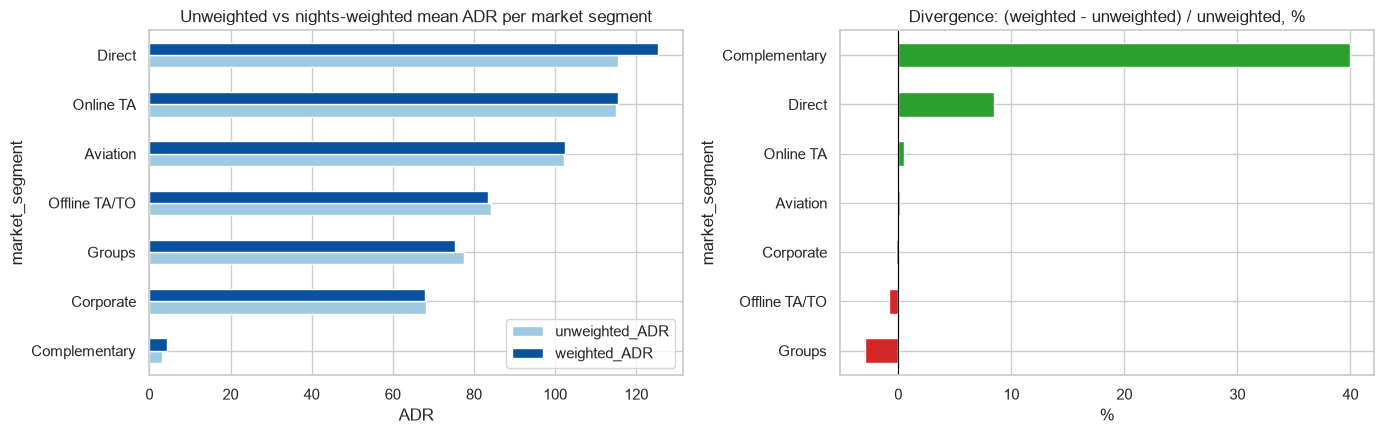

In [9]:
# Why does the top segment diverge? Look at ADR and hotel mix by length-of-stay bucket inside that segment.
seg_df = stays[stays['market_segment'] == top_seg].copy()
seg_df['stay_bucket'] = pd.cut(seg_df['total_nights'], bins=[0, 1, 3, 7, 14, 100],
                               labels=['1', '2-3', '4-7', '8-14', '15+'])
bucket_tbl = seg_df.groupby('stay_bucket', observed=True).agg(
    n_bookings=('adr', 'size'), room_nights=('total_nights', 'sum'), mean_ADR=('adr', 'mean'),
    share_resort_hotel=('hotel', lambda s: (s == 'Resort Hotel').mean()),
    share_arrivals_Nov_to_Mar=('arrival_month', lambda s: s.isin([11, 12, 1, 2, 3]).mean()))
bucket_tbl['share_of_room_nights'] = bucket_tbl['room_nights'] / bucket_tbl['room_nights'].sum()
print(f'Segment "{top_seg}" by length of stay:')
display(bucket_tbl.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_tbl = wtab.drop(index='ALL')[['unweighted_ADR', 'weighted_ADR']].sort_values('unweighted_ADR')
plot_tbl.plot.barh(ax=axes[0], color=['#9ecae1', '#08519c'])
axes[0].set_title('Unweighted vs nights-weighted mean ADR per market segment')
axes[0].set_xlabel('ADR')
wtab.drop(index='ALL')['diff_pct'].sort_values().plot.barh(
    ax=axes[1], color=['#d62728' if v < 0 else '#2ca02c' for v in wtab.drop(index='ALL')['diff_pct'].sort_values()])
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_title('Divergence: (weighted - unweighted) / unweighted, %')
axes[1].set_xlabel('%')
plt.tight_layout()
plt.show()

**Interpretation 1.2.** Over all realised stays the nights-weighted ADR is 102.20 vs the plain mean of 101.01 (+1.18%). The divergence differs a lot by segment. The table confirms the identity x̄_w − x̄ = cov(ADR, nights) / mean(nights): weighting raises the mean exactly where longer stays are more expensive. **The largest relative divergence is *Complementary*: 3.17 → 4.43 (+39.9%)**, followed by *Direct* (115.50 → 125.26, +8.5%, the largest absolute gap of +9.77). *Groups* moves the other way (−3.0%): long group stays get volume discounts.

**Hypothesis for Complementary:** the segment mixes two kinds of "free" stays. One-night complementary bookings are genuine free rooms (inspections, compensation, partners): 354 bookings with mean ADR 1.27. Longer complementary stays are partly charged (mean ADR 5.16 for 2–3 nights, 11.94 for 4–7 nights), and they are more often at the Resort Hotel (share 17% → 46%). The unweighted mean counts every short free night as much as a long paid stay, while weighting by nights gives the longer, partly paid stays 67% of the weight. The +39.9% is large in relative terms only because the base is ~3; in money terms the *Direct* gap is the more important one for revenue analysis.

## Task 1.3 — Loss of variability through aggregation (CV vs. granularity)

`adr` is aggregated along the time hierarchy **booking → day → week → month → quarter → year** (group statistic = mean ADR of all bookings arriving in that period). For every level we compute CV = std / mean of the resulting values. Besides CV, the column `variance_kept_pct` shows which share of the booking-level variance of ADR is still represented by the differences between the group means (between-group sum of squares / total sum of squares).

In [10]:
def cv(s):
    s = pd.Series(s).dropna()
    return s.std(ddof=1) / s.mean()


LEVELS = [('Booking (raw)', None), ('Day', 'D'), ('Week', 'W'), ('Month', 'MS'), ('Quarter', 'QS'), ('Year', 'YS')]
SCOPES = {'All bookings': df,
          'City Hotel': df[df['hotel'] == 'City Hotel'],
          'Resort Hotel': df[df['hotel'] == 'Resort Hotel']}

rows = []
for scope, data in SCOPES.items():
    grand_mean = data['adr'].mean()
    total_ss = ((data['adr'] - grand_mean) ** 2).sum()
    for level, freq in LEVELS:
        if freq is None:
            values, kept = data['adr'], 1.0
        else:
            grp = data.groupby(pd.Grouper(key='arrival_date', freq=freq))['adr'].agg(['mean', 'size'])
            grp = grp[grp['size'] > 0]
            values = grp['mean']
            kept = (grp['size'] * (grp['mean'] - grand_mean) ** 2).sum() / total_ss
        rows.append({'scope': scope, 'level': level, 'n_points': len(values), 'mean': values.mean(),
                     'std': values.std(ddof=1), 'CV': cv(values), 'variance_kept_pct': 100 * kept})

cv_tbl = pd.DataFrame(rows)
cv_tbl['CV_relative_to_raw'] = cv_tbl['CV'] / cv_tbl.groupby('scope')['CV'].transform('first')
display(cv_tbl.round(3))

,scope,level,n_points,mean,std,CV,variance_kept_pct,CV_relative_to_raw
0,All bookings,Booking (raw),119208,101.926,48.042,0.471,100.000,1.000
1,All bookings,Day,793,98.313,29.014,0.295,33.146,0.626
2,All bookings,Week,114,98.502,27.276,0.277,29.711,0.587
3,All bookings,Month,26,98.562,26.422,0.268,27.810,0.569
4,All bookings,Quarter,9,101.055,27.447,0.272,25.426,0.576
5,All bookings,Year,3,100.155,13.848,0.138,4.424,0.293
6,City Hotel,Booking (raw),79162,105.436,39.117,0.371,100.000,1.000
7,City Hotel,Day,793,100.818,22.616,0.224,28.929,0.605
8,City Hotel,Week,114,100.641,20.490,0.204,24.175,0.549
9,City Hotel,Month,26,100.924,19.662,0.195,21.598,0.525


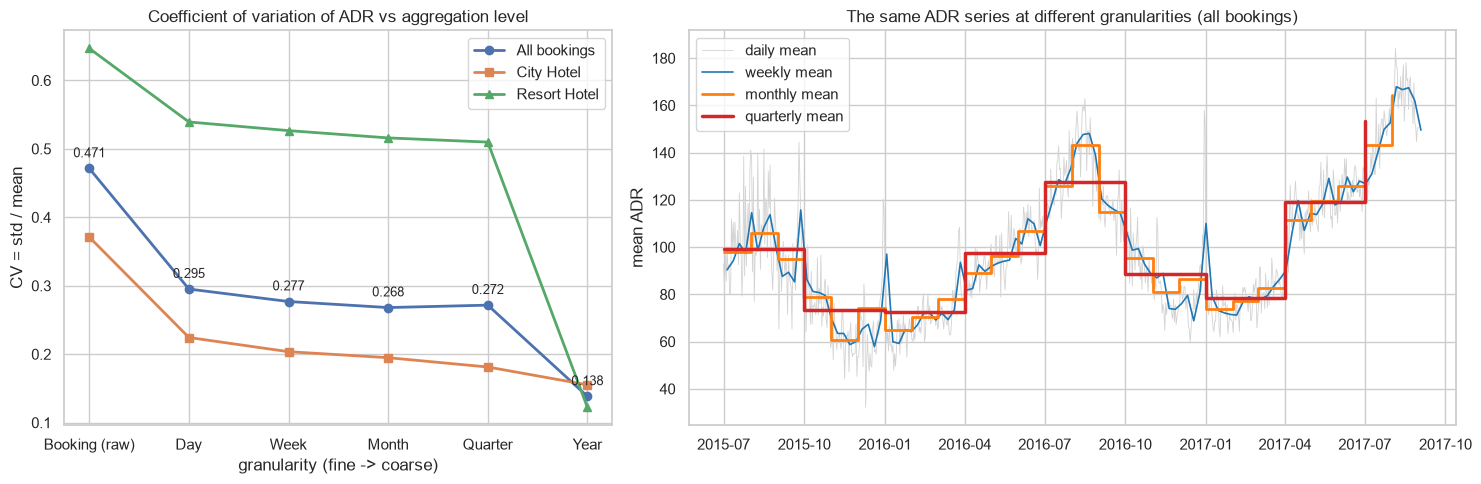

In [11]:
level_names = [lvl for lvl, _ in LEVELS]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.4]})

for scope, marker in zip(SCOPES, ['o', 's', '^']):
    sub = cv_tbl[cv_tbl['scope'] == scope]
    axes[0].plot(level_names, sub['CV'], marker=marker, lw=2, label=scope)
for x, y in enumerate(cv_tbl[cv_tbl['scope'] == 'All bookings']['CV']):
    axes[0].annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
axes[0].set_title('Coefficient of variation of ADR vs aggregation level')
axes[0].set_xlabel('granularity (fine -> coarse)')
axes[0].set_ylabel('CV = std / mean')
axes[0].legend()

daily = df.groupby('arrival_date')['adr'].mean()
weekly = df.groupby(pd.Grouper(key='arrival_date', freq='W'))['adr'].mean()
monthly = df.groupby(pd.Grouper(key='arrival_date', freq='MS'))['adr'].mean()
quarterly = df.groupby(pd.Grouper(key='arrival_date', freq='QS'))['adr'].mean()
axes[1].plot(daily.index, daily.values, lw=0.6, color='lightgray', label='daily mean')
axes[1].plot(weekly.index, weekly.values, lw=1.2, color='tab:blue', label='weekly mean')
axes[1].step(monthly.index, monthly.values, where='post', lw=2, color='tab:orange', label='monthly mean')
axes[1].step(quarterly.index, quarterly.values, where='post', lw=2.5, color='tab:red', label='quarterly mean')
axes[1].set_title('The same ADR series at different granularities (all bookings)')
axes[1].set_ylabel('mean ADR')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

**Interpretation 1.3.** For all bookings CV falls from **0.471 (raw) to 0.295 at day level**. Only 33.1% of the booking-level variance survives: two thirds of the variation of ADR are differences *between bookings of the same day* (hotel, room type, segment), and the very first aggregation step already hides them. From day to week to month CV barely moves (0.295 → 0.277 → 0.268), and 27.8% of the variance is still kept at month level. The right plot shows why: the day-to-day noise disappears, but the strong seasonal cycle (≈ 60–75 in winter vs 140–165 in August) is fully preserved in monthly and even quarterly means (CV 0.272, 25.4% kept). **The real loss of meaningful information happens at the year level: CV halves from 0.272 to 0.138 and only 4.4% of the variance is left**, because every year averages summer peaks with winter troughs. The year level is additionally misleading because 2015 only covers Jul–Dec and 2017 only Jan–Aug. The effect differs by hotel: the Resort Hotel keeps 60.3% of its variance at month level (strong seasonality) but only 2.5% at year level, while the City Hotel already loses 71% at day level. So for the Resort Hotel the month is the coarsest safe granularity; for the City Hotel even daily aggregation hides most of the price structure.

---
# Part 2. Sampling

## Task 2.1 — Reservoir sampling from scratch (k = 500)

Algorithm R: keep the first *k* items; for the *i*-th item (0-based, *i* ≥ *k*) draw *j* uniformly from {0, …, *i*} and replace `reservoir[j]` if *j* < *k*. After the whole stream every item is in the reservoir with probability *k / N*, and the stream length *N* never has to be known in advance. The only random primitive is one integer draw per item (`random.Random.randrange`, which is ~10× faster per scalar call than `numpy.Generator.integers` — important for 200 passes over 119k rows).

In [12]:
def reservoir_sample(stream, k, seed=None):
    rng = random.Random(seed)
    reservoir = []
    for i, item in enumerate(stream):
        if i < k:
            reservoir.append(item)
        else:
            j = rng.randrange(i + 1)          # uniform integer in [0, i]
            if j < k:
                reservoir[j] = item
    return reservoir


K = 500
# The DataFrame is consumed as a stream: itertuples yields one row at a time.
t0 = time.perf_counter()
sample_rows = reservoir_sample(df.itertuples(index=False), K, seed=SEED)
res_df = pd.DataFrame(sample_rows, columns=df.columns)
print(f'Reservoir sample: {res_df.shape}, {time.perf_counter() - t0:.2f}s for one pass over {N:,} rows')
display(pd.DataFrame({'full data': df[['adr', 'lead_time', 'total_nights', 'is_canceled']].mean(),
                      'reservoir sample (k=500)': res_df[['adr', 'lead_time', 'total_nights', 'is_canceled']].mean()}).round(3))

Reservoir sample: (500, 32), 0.56s for one pass over 119,208 rows


,full data,reservoir sample (k=500)
adr,101.926,102.887
lead_time,104.109,113.488
total_nights,3.426,3.570
is_canceled,0.371,0.386


In [13]:
# Empirical check of uniformity: 200 independent runs over the stream of row positions 0..N-1
RUNS = 200
selection_counts = np.zeros(N, dtype=np.int64)
t0 = time.perf_counter()
for r in range(RUNS):
    chosen = reservoir_sample(range(N), K, seed=SEED + r)
    assert len(set(chosen)) == K
    selection_counts[chosen] += 1
print(f'{RUNS} runs finished in {time.perf_counter() - t0:.1f}s')

p_theory = K / N
expected_per_row = RUNS * p_theory
print(f'Theoretical inclusion probability k/N = {p_theory:.5f}; expected selections per row = {expected_per_row:.3f}')
print(f'Observed mean selections per row = {selection_counts.mean():.3f}, variance = {selection_counts.var():.3f} '
      f'(Binomial variance = {RUNS * p_theory * (1 - p_theory):.3f})')

# Test 1: the per-row selection counts must follow Binomial(RUNS, k/N)
max_bin = 4
obs_counts = np.array([(selection_counts == c).sum() for c in range(max_bin)] + [(selection_counts >= max_bin).sum()])
exp_probs = np.append(stats.binom.pmf(np.arange(max_bin), RUNS, p_theory), stats.binom.sf(max_bin - 1, RUNS, p_theory))
chi_binom, p_binom = stats.chisquare(obs_counts, exp_probs * N)

# Test 2: no positional bias — early, middle and late rows of the stream are selected equally often
N_BINS = 20
pos_bins = np.array_split(selection_counts, N_BINS)
bin_totals = np.array([b.sum() for b in pos_bins])
bin_sizes = np.array([len(b) for b in pos_bins])
chi_pos, p_pos = stats.chisquare(bin_totals, RUNS * K * bin_sizes / N)

display(pd.DataFrame({'selected c times': [str(c) for c in range(max_bin)] + [f'>={max_bin}'],
                      'observed rows': obs_counts, 'expected rows (Binomial)': (exp_probs * N).round(1)}))
print(f'Chi-square vs Binomial: chi2 = {chi_binom:.2f}, p = {p_binom:.3f}')
print(f'Chi-square uniformity over {N_BINS} stream-position bins: chi2 = {chi_pos:.2f}, p = {p_pos:.3f}')

200 runs finished in 7.3s
Theoretical inclusion probability k/N = 0.00419; expected selections per row = 0.839
Observed mean selections per row = 0.839, variance = 0.836 (Binomial variance = 0.835)


,selected c times,observed rows,expected rows (Binomial)
0,0,51408,"51,430.700"
1,1,43404,"43,325.400"
2,2,18071,"18,157.500"
3,3,5087,"5,047.700"
4,>=4,1238,"1,246.700"


Chi-square vs Binomial: chi2 = 0.93, p = 0.920
Chi-square uniformity over 20 stream-position bins: chi2 = 23.65, p = 0.210


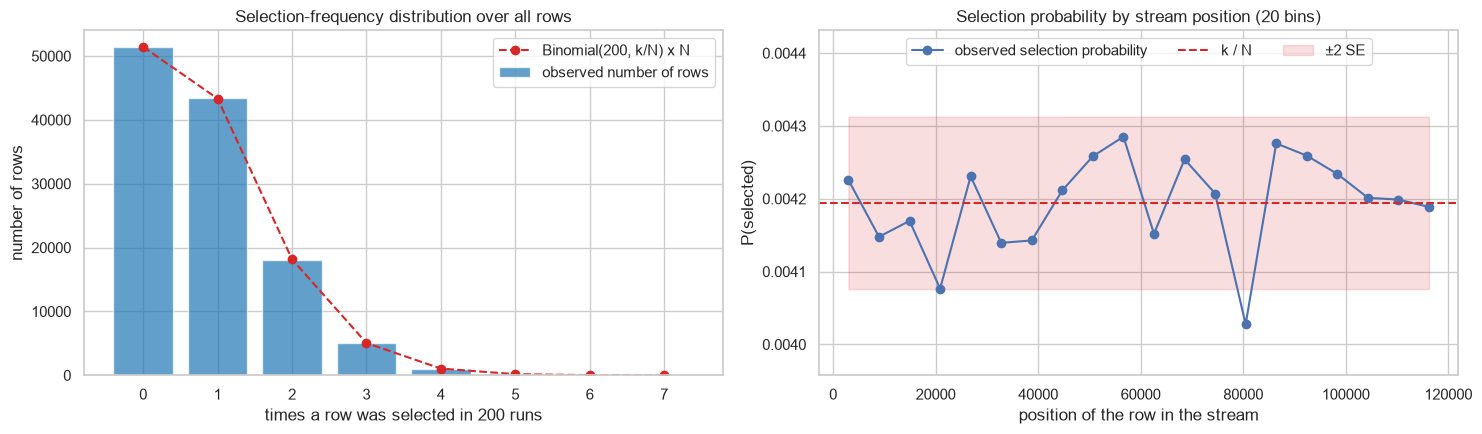

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
c_vals = np.arange(0, selection_counts.max() + 1)
observed_freq = np.array([(selection_counts == c).sum() for c in c_vals])
axes[0].bar(c_vals, observed_freq, color='tab:blue', alpha=0.7, label='observed number of rows')
axes[0].plot(c_vals, stats.binom.pmf(c_vals, RUNS, p_theory) * N, 'o--', color='tab:red', label=f'Binomial({RUNS}, k/N) x N')
axes[0].set_xlabel(f'times a row was selected in {RUNS} runs')
axes[0].set_ylabel('number of rows')
axes[0].set_title('Selection-frequency distribution over all rows')
axes[0].legend()

bin_prob = bin_totals / (RUNS * bin_sizes)
se = np.sqrt(p_theory * (1 - p_theory) / (RUNS * bin_sizes))
centers = np.cumsum(bin_sizes) - bin_sizes / 2
axes[1].plot(centers, bin_prob, 'o-', label='observed selection probability')
axes[1].axhline(p_theory, color='tab:red', ls='--', label='k / N')
axes[1].fill_between(centers, p_theory - 2 * se, p_theory + 2 * se, color='tab:red', alpha=0.15, label='±2 SE')
axes[1].set_xlabel('position of the row in the stream')
axes[1].set_ylabel('P(selected)')
axes[1].set_title(f'Selection probability by stream position ({N_BINS} bins)')
axes[1].set_ylim(p_theory - 4 * se.max(), p_theory + 4 * se.max())
axes[1].legend(loc='upper center', ncol=3)
plt.tight_layout()
plt.show()

**Interpretation 2.1.** One pass of the reservoir over the 119,208 rows takes about half a second, and the k = 500 sample already reproduces the population well (cancel rate 0.386 vs 0.371, mean ADR 102.9 vs 101.9). Over 200 runs every row should be selected Binomial(200, 500/119,208) times, i.e. 0.839 times on average. **The observed mean is 0.839 and the variance 0.836 (theory 0.835)**, and the histogram lies on the binomial curve (χ² = 0.93, p = 0.92). The right plot checks the key property of Algorithm R — no bias toward early or late items of the stream. All 20 position bins stay within ±2 SE of k/N (χ² = 23.65 with 19 df, p = 0.21). So neither test rejects equal inclusion probability, and the implementation is correct. Note that with N ≫ k the expected count per row is below 1, which is why the check is done on the *distribution* of counts and on position bins rather than on individual rows.

## Task 2.2 — Simple random vs. stratified vs. convenience sampling (10% of the data)

In [15]:
TARGET = 'is_canceled'
n_target = int(round(0.10 * N))
pop_dist = df[TARGET].value_counts(normalize=True).sort_index()


def kl_divergence(p, q, eps=1e-12):
    # D_KL(P || Q) = Σ_c P(c) · ln( P(c) / Q(c) )   P = class distribution of the sample, Q = full data
    p = np.asarray(p, dtype=float) + eps
    q = np.asarray(q, dtype=float) + eps
    p, q = p / p.sum(), q / q.sum()
    return float(np.sum(p * np.log(p / q)))


def chi_squared(observed_counts, population_dist):
    # χ² = Σ_c (O_c − E_c)² / E_c,   E_c = n_sample · Q(c)
    observed_counts = np.asarray(observed_counts, dtype=float)
    expected = observed_counts.sum() * np.asarray(population_dist, dtype=float)
    chi2 = float(np.sum((observed_counts - expected) ** 2 / expected))
    return chi2, float(stats.chi2.sf(chi2, df=len(expected) - 1))


samples = {
    '(a) Simple random': df.sample(n=n_target, random_state=SEED),
    '(b) Stratified on is_canceled': train_test_split(df, train_size=n_target, stratify=df[TARGET], random_state=SEED)[0],
    '(c) Convenience: first 10% of rows': df.head(n_target),
    "(c') Convenience: top-10% lead_time": df.nlargest(n_target, 'lead_time'),
}

majority_full = pop_dist.idxmax()
rows = []
for name, s in samples.items():
    counts = s[TARGET].value_counts().reindex(pop_dist.index, fill_value=0)
    dist = counts / counts.sum()
    chi2, p = chi_squared(counts, pop_dist)
    majority = int(dist.idxmax())
    rows.append({'method': name, 'n': len(s), 'cancel_rate': dist[1], 'abs_error_pp': 100 * abs(dist[1] - pop_dist[1]),
                 'KL(sample || full)': kl_divergence(dist, pop_dist), 'chi2': chi2, 'p_value': p,
                 'majority_class': majority,
                 'majority-rule accuracy on full data': (df[TARGET] == majority).mean()})
sampling_tbl = pd.DataFrame(rows).set_index('method')
print(f'Full data: n = {N:,}, cancel rate = {pop_dist[1]:.4f}; sample size = {n_target:,}')
display(sampling_tbl.style.format({'n': '{:,}', 'cancel_rate': '{:.4f}', 'abs_error_pp': '{:.3f}',
                                   'KL(sample || full)': '{:.2e}', 'chi2': '{:.3f}', 'p_value': '{:.3g}',
                                   'majority-rule accuracy on full data': '{:.3f}'}))

# verify manual KL against scipy
s_a = samples['(a) Simple random'][TARGET].value_counts(normalize=True).sort_index()
assert np.isclose(kl_divergence(s_a, pop_dist), stats.entropy(s_a, pop_dist), atol=1e-9)

conv = samples['(c) Convenience: first 10% of rows']
print('Composition of the first-10% sample:', conv['hotel'].value_counts().to_dict(),
      '| arrival years:', sorted(conv['arrival_date_year'].unique()))

Full data: n = 119,208, cancel rate = 0.3708; sample size = 11,921


,n,cancel_rate,abs_error_pp,KL(sample || full),chi2,p_value,majority_class,majority-rule accuracy on full data
method,,,,,,,,
(a) Simple random,"11,921",0.3749,0.412,3.63e-05,0.868,0.352,0,0.629
(b) Stratified on is_canceled,"11,921",0.3708,0.001,2.39e-10,0.000,0.998,0,0.629
(c) Convenience: first 10% of rows,"11,921",0.6924,32.163,2.12e-01,5285.780,0,1,0.371
(c') Convenience: top-10% lead_time,"11,921",0.6729,30.217,1.87e-01,4665.456,0,1,0.371


Composition of the first-10% sample: {'Resort Hotel': 11921} | arrival years: [np.int64(2015), np.int64(2016), np.int64(2017)]


,mean,50%,max
Simple random,3.89e-05,1.80e-05,2.18e-04
Stratified,2.39e-10,2.39e-10,2.39e-10


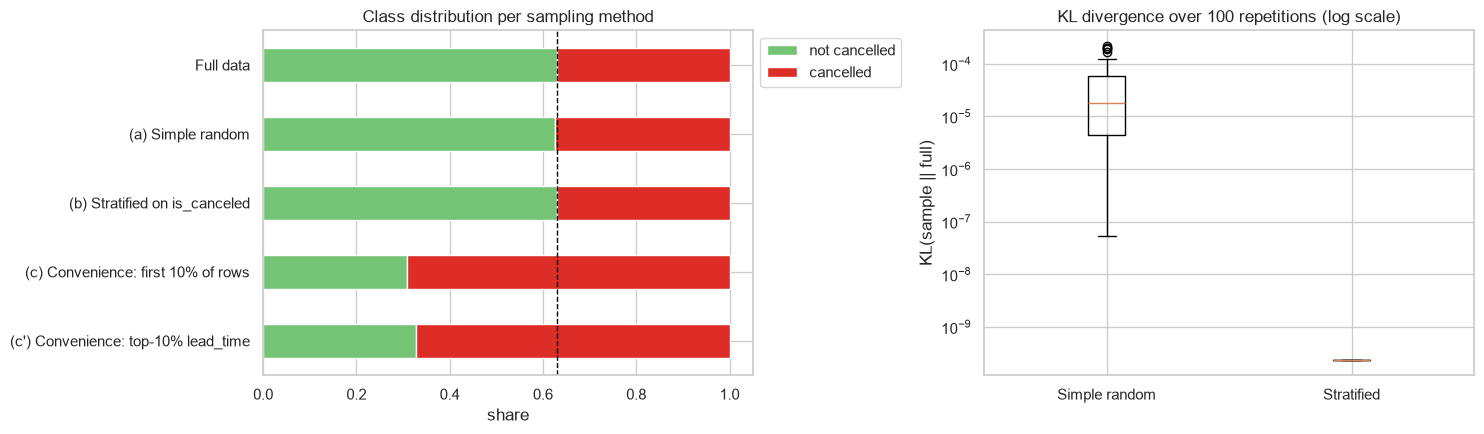

In [16]:
# Robustness: repeat random and stratified sampling with 100 different seeds
y_full = df[TARGET]
kl_rep = {'Simple random': [], 'Stratified': []}
for s in range(100):
    srs = y_full.sample(n=n_target, random_state=s).value_counts(normalize=True).reindex(pop_dist.index, fill_value=0)
    strat = train_test_split(y_full, train_size=n_target, stratify=y_full, random_state=s)[0] \
        .value_counts(normalize=True).reindex(pop_dist.index, fill_value=0)
    kl_rep['Simple random'].append(kl_divergence(srs, pop_dist))
    kl_rep['Stratified'].append(kl_divergence(strat, pop_dist))
kl_rep = pd.DataFrame(kl_rep)
display(kl_rep.describe().loc[['mean', '50%', 'max']].T.style.format('{:.2e}'))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
props = pd.DataFrame({name: s[TARGET].value_counts(normalize=True).sort_index() for name, s in samples.items()})
props.insert(0, 'Full data', pop_dist)
props.T.rename(columns={0: 'not cancelled', 1: 'cancelled'}).plot.barh(stacked=True, ax=axes[0], color=['#74c476', '#de2d26'])
axes[0].axvline(pop_dist[0], color='black', ls='--', lw=1)
axes[0].set_title('Class distribution per sampling method')
axes[0].set_xlabel('share')
axes[0].invert_yaxis()
axes[0].legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
axes[1].boxplot([kl_rep['Simple random'], kl_rep['Stratified']], showfliers=True)
axes[1].set_xticks([1, 2], ['Simple random', 'Stratified'])
axes[1].set_yscale('log')
axes[1].set_ylabel('KL(sample || full)')
axes[1].set_title('KL divergence over 100 repetitions (log scale)')
plt.tight_layout()
plt.show()

**Interpretation 2.2.** Stratified sampling reproduces the class ratio almost exactly: cancel rate 0.3708, **KL = 2.4·10⁻¹⁰**, χ² ≈ 0 (p = 0.998), and the tiny KL is only a rounding effect of integer counts. Simple random sampling is also unbiased but noisy: this seed gives 0.3749 (+0.41 pp, **KL = 3.6·10⁻⁵**, χ² = 0.87, p = 0.35), and over 100 seeds its KL reaches 2.2·10⁻⁴. **The convenience sample of the first 10% of rows degrades class balance the most: cancel rate 0.692 (+32.2 pp), KL = 0.212 (~5,800× larger than random), χ² = 5,286 (p ≈ 0).** The file is sorted by hotel, so these rows are 100% Resort Hotel. Taking the 10% longest lead times gives almost the same bias (0.673, KL = 0.187), because long lead times are strongly associated with cancellations. For a classifier this is a prior shift: the majority class flips to "cancelled", so even the majority baseline drops from 62.9% to 37.1% accuracy on the real data. A model trained on this sample learns prior odds of 2.25 instead of 0.59 (≈3.8× too high), which shifts the logistic intercept by ≈ +1.34 and makes it over-predict cancellations. On top of that, the sample contains only one hotel, so the model has never seen City Hotel bookings (covariate shift).

## Task 2.3 — Empirical sample size: bootstrap CI of the mean ADR

For each n a stratified sample (on `is_canceled`) is drawn, then 1000 bootstrap resamples of size n are taken **with replacement** from it; the 2.5% and 97.5% percentiles of the 1000 bootstrap means form the 95% CI.

In [17]:
KEY = 'adr'
SIZES = [100, 250, 500, 1000, 2500, 5000]
B = 1000
full_mean = df[KEY].mean()
full_std = df[KEY].std()
threshold = 0.05 * full_mean
rng = np.random.default_rng(SEED)

rows = []
for n in SIZES:
    sample = train_test_split(df, train_size=n, stratify=df[TARGET], random_state=SEED)[0]
    x = sample[KEY].to_numpy()
    boot_idx = rng.integers(0, n, size=(B, n))           # B bootstrap resamples, each of size n, with replacement
    boot_means = x[boot_idx].mean(axis=1)
    lo, hi = np.percentile(boot_means, [2.5, 97.5])
    rows.append({'n': n, 'sample_mean': x.mean(), 'CI_low': lo, 'CI_high': hi, 'CI_width': hi - lo,
                 'width_pct_of_full_mean': 100 * (hi - lo) / full_mean,
                 'contains_full_mean': lo <= full_mean <= hi, 'width < 5%': (hi - lo) < threshold})
boot_tbl = pd.DataFrame(rows).set_index('n')
print(f'Full-data mean ADR = {full_mean:.2f}; 5% threshold for the CI width = {threshold:.2f}')
display(boot_tbl.round(2))

ok = boot_tbl[boot_tbl['width < 5%']]
n_min = ok.index.min() if len(ok) else None
n_theory = (2 * 1.96 * full_std / threshold) ** 2
print(f'Smallest tested n with CI width < 5% of the full mean: {n_min}')
print(f'Normal-approximation estimate of the exact minimum: n ≈ (2·1.96·σ / (0.05·μ))² = {n_theory:,.0f}')

Full-data mean ADR = 101.93; 5% threshold for the CI width = 5.10


,sample_mean,CI_low,CI_high,CI_width,width_pct_of_full_mean,contains_full_mean,width < 5%
n,,,,,,,
100,98.990,89.280,109.100,19.820,19.440,True,False
250,106.430,100.030,113.490,13.450,13.200,True,False
500,100.640,96.050,105.420,9.370,9.190,True,False
1000,102.870,99.890,106.000,6.100,5.990,True,False
2500,103.500,101.570,105.370,3.800,3.730,True,True
5000,103.090,101.650,104.460,2.810,2.750,True,True


Smallest tested n with CI width < 5% of the full mean: 2500
Normal-approximation estimate of the exact minimum: n ≈ (2·1.96·σ / (0.05·μ))² = 1,366


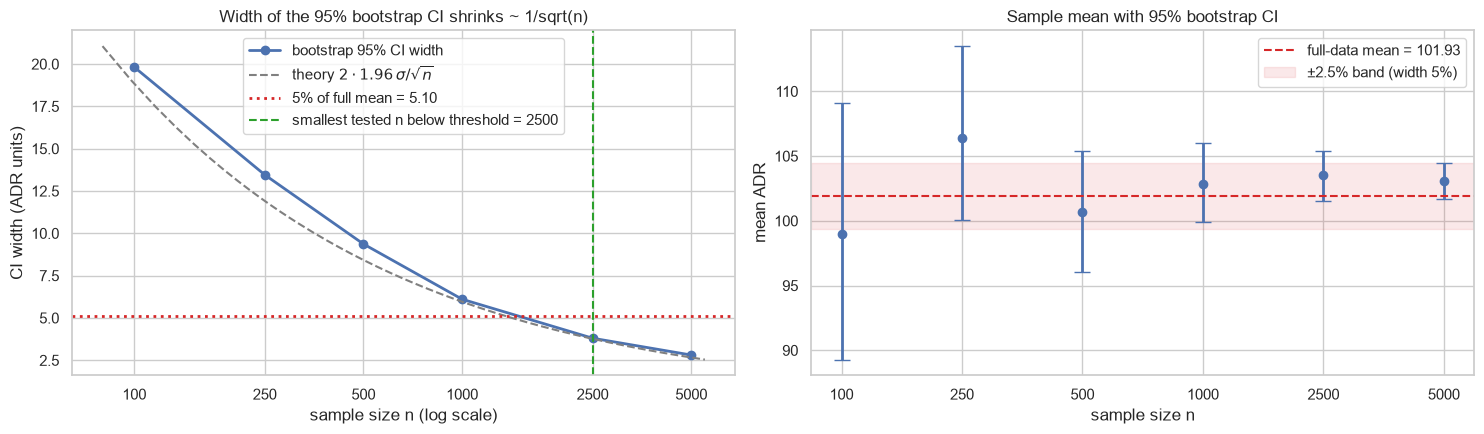

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
n_grid = np.linspace(80, 5500, 300)
axes[0].plot(boot_tbl.index, boot_tbl['CI_width'], 'o-', lw=2, label='bootstrap 95% CI width')
axes[0].plot(n_grid, 2 * 1.96 * full_std / np.sqrt(n_grid), '--', color='gray', label=r'theory $2\cdot1.96\,\sigma/\sqrt{n}$')
axes[0].axhline(threshold, color='tab:red', ls=':', lw=2, label=f'5% of full mean = {threshold:.2f}')
if n_min is not None:
    axes[0].axvline(n_min, color='tab:green', ls='--', label=f'smallest tested n below threshold = {n_min}')
axes[0].set_xscale('log')
axes[0].set_xticks(SIZES, [str(s) for s in SIZES])
axes[0].set_xlabel('sample size n (log scale)')
axes[0].set_ylabel('CI width (ADR units)')
axes[0].set_title('Width of the 95% bootstrap CI shrinks ~ 1/sqrt(n)')
axes[0].legend()

axes[1].errorbar(range(len(SIZES)), boot_tbl['sample_mean'],
                 yerr=[boot_tbl['sample_mean'] - boot_tbl['CI_low'], boot_tbl['CI_high'] - boot_tbl['sample_mean']],
                 fmt='o', capsize=6, lw=2)
axes[1].axhline(full_mean, color='tab:red', ls='--', label=f'full-data mean = {full_mean:.2f}')
axes[1].axhspan(full_mean - threshold / 2, full_mean + threshold / 2, color='tab:red', alpha=0.1, label='±2.5% band (width 5%)')
axes[1].set_xticks(range(len(SIZES)), [str(s) for s in SIZES])
axes[1].set_xlabel('sample size n')
axes[1].set_ylabel('mean ADR')
axes[1].set_title('Sample mean with 95% bootstrap CI')
axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretation 2.3.** The bootstrap CI width follows the theoretical 1/√n law closely (dashed curve): **19.82 → 13.45 → 9.37 → 6.10 → 3.80 → 2.81 ADR units** for n = 100 … 5000, i.e. 19.4% → 2.8% of the full-data mean of 101.93. All six intervals contain the true mean. The 5% threshold equals 5.10. **n = 1000 is still slightly too wide (6.10 = 6.0%), and the smallest tested size that satisfies the requirement is n = 2500 (3.80 = 3.7%).** The normal approximation n ≈ (2·1.96·σ / 0.05·μ)² = 1,366 shows that the true minimum lies between the grid points 1000 and 2500. Beyond that the returns diminish: doubling n from 2500 to 5000 only narrows the interval by 1 unit. So ≈ 2.5k stratified rows (about 2% of the data) are enough to estimate the average price within ±2.5%; the whole dataset is only needed for rare subgroups or model training.

---
# Part 3. Feature Subset Selection

Feature matrix for the whole Part 3 (target `is_canceled`):
* **numeric features** — all numeric columns after cleaning, plus `arrival_month` (month name → 1..12) and `total_nights` (weekend + week nights, needed in Task 1.2);
* **categorical features** — one-hot encoded; `country` is reduced to the top-10 countries + `Other` to avoid 170+ sparse dummies.

In [19]:
numeric_candidates = ['lead_time', 'total_nights', 'stays_in_weekend_nights', 'stays_in_week_nights',
                      'arrival_date_year', 'arrival_month', 'arrival_date_week_number', 'arrival_date_day_of_month',
                      'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
                      'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr',
                      'required_car_parking_spaces', 'total_of_special_requests', 'has_agent', 'has_company']

top_countries = df['country'].value_counts().head(10).index
df['country_grouped'] = df['country'].where(df['country'].isin(top_countries), 'Other')
categorical_features = ['hotel', 'meal', 'market_segment', 'distribution_channel', 'deposit_type',
                        'customer_type', 'reserved_room_type', 'country_grouped']

X_all = pd.concat([df[numeric_candidates].astype(float),
                   pd.get_dummies(df[categorical_features], prefix_sep='=', dtype=float)], axis=1)
y_all = df[TARGET]
print('Feature matrix:', X_all.shape, f'({len(numeric_candidates)} numeric + {X_all.shape[1] - len(numeric_candidates)} dummies)')

Feature matrix: (119208, 68) (21 numeric + 47 dummies)


## Task 3.1 — Multicollinearity: iterative VIF elimination

VIF of feature *j*: $VIF_j = 1 / (1 - R_j^2)$, where $R_j^2$ comes from regressing feature *j* on all other features **with an intercept**. We add the intercept explicitly with `add_constant` (statsmodels 0.15 also centers the columns by default, `standardize=True`, which has the same effect). The second column of the first table shows what happens with the classic uncentered computation without an intercept (`standardize=False`): features far from zero, such as `arrival_date_year` ≈ 2016, get absurd VIFs because they replace the missing intercept.

Note: `statsmodels` clips $R^2$ at $1 - 10^{-15}$, so an **exact** linear dependency shows up as VIF ≈ $10^{15}$ instead of ∞. Its "poorly conditioned design matrix" warning is expected here for the same reason and is suppressed.

In [20]:
def compute_vif(X, with_constant=True):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', UserWarning)          # condition-number warning, see note above
        with np.errstate(divide='ignore', invalid='ignore'):
            if with_constant:
                Xc = add_constant(X, has_constant='add').values
                values = [variance_inflation_factor(Xc, i + 1) for i in range(X.shape[1])]
            else:
                values = [variance_inflation_factor(X.values, i, standardize=False) for i in range(X.shape[1])]
    return pd.Series(values, index=X.columns)


X_vif = df[numeric_candidates].astype(float)
print(f'Condition number of the standardized numeric matrix: {np.linalg.cond(StandardScaler().fit_transform(X_vif)):.2e}')
vif_compare = pd.DataFrame({'VIF (with intercept, correct)': compute_vif(X_vif, True),
                            'VIF (no intercept, uncentered — wrong)': compute_vif(X_vif, False)})
display(vif_compare.sort_values('VIF (with intercept, correct)', ascending=False)
        .style.format('{:,.2f}').map(lambda v: 'background-color: #fcbba1' if v >= 10 else ''))

Condition number of the standardized numeric matrix: 1.87e+14


,"VIF (with intercept, correct)","VIF (no intercept, uncentered — wrong)"
total_nights,"1,000,799,917,193,443.50","1,000,799,917,193,443.50"
stays_in_week_nights,"1,000,799,917,193,443.50","1,000,799,917,193,443.50"
stays_in_weekend_nights,"1,000,799,917,193,443.50","1,000,799,917,193,443.50"
arrival_date_week_number,"1,159.71","4,646.77"
arrival_month,"1,134.06","5,113.19"
arrival_date_day_of_month,10.95,38.45
arrival_date_year,2.04,100.63
has_company,1.69,1.79
has_agent,1.62,11.86
adr,1.41,7.30


In [21]:
VIF_THRESHOLD = 10
X_current = X_vif.copy()
removed_features, log_rows = [], []
step = 0
while True:
    vif = compute_vif(X_current)
    if vif.max() < VIF_THRESHOLD:
        break
    worst = vif.idxmax()
    step += 1
    top3 = ', '.join(f'{f}={v:,.1f}' for f, v in vif.sort_values(ascending=False).head(3).items())
    log_rows.append({'step': step, 'removed_feature': worst, 'its_VIF': vif[worst], 'top-3 VIFs before removal': top3})
    removed_features.append(worst)
    X_current = X_current.drop(columns=worst)

vif_log = pd.DataFrame(log_rows).set_index('step')
final_vif = compute_vif(X_current).sort_values(ascending=False)
vif_numeric_kept = list(X_current.columns)
print(f'Removed {len(removed_features)} feature(s): {removed_features}')
display(vif_log)
print(f'Final VIFs ({len(vif_numeric_kept)} numeric features, all < {VIF_THRESHOLD}):')
display(final_vif.to_frame('VIF').T.round(2))

Removed 2 feature(s): ['total_nights', 'arrival_date_week_number']


,removed_feature,its_VIF,top-3 VIFs before removal
step,,,
1,total_nights,"1,000,799,917,193,443.500","total_nights=1,000,799,917,193,443.5, stays_in..."
2,arrival_date_week_number,"1,159.724","arrival_date_week_number=1,159.7, arrival_mont..."


Final VIFs (19 numeric features, all < 10):


,has_company,arrival_date_year,has_agent,arrival_month,adr,stays_in_week_nights,stays_in_weekend_nights,is_repeated_guest,previous_bookings_not_canceled,lead_time,children,adults,total_of_special_requests,previous_cancellations,days_in_waiting_list,required_car_parking_spaces,booking_changes,babies,arrival_date_day_of_month
VIF,1.690,1.640,1.620,1.560,1.410,1.370,1.340,1.310,1.280,1.220,1.140,1.140,1.110,1.060,1.050,1.040,1.040,1.020,1.010


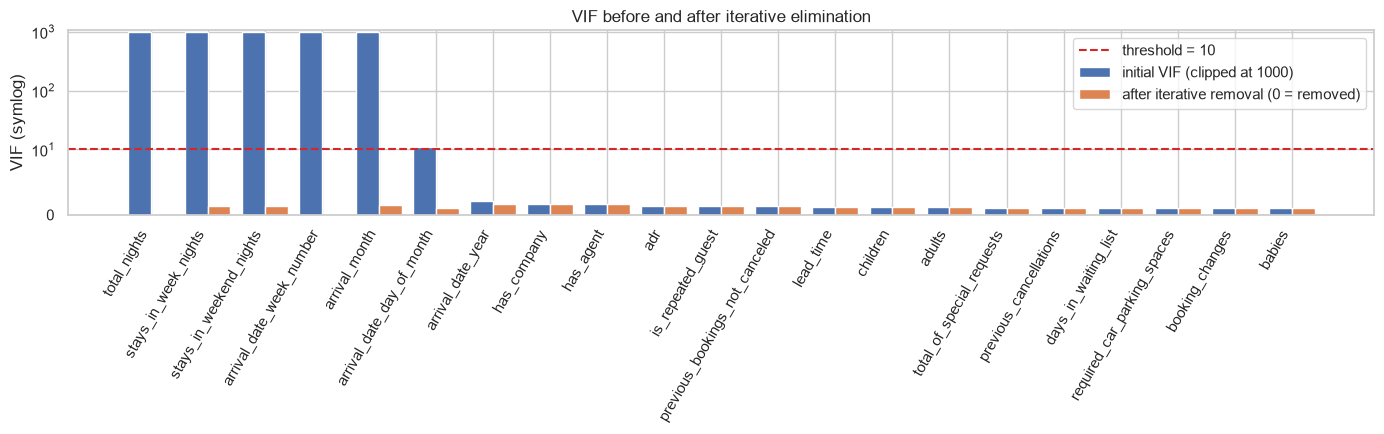

In [22]:
fig, ax = plt.subplots(figsize=(14, 4.5))
initial = compute_vif(X_vif).clip(upper=1e3)
order = initial.sort_values(ascending=False).index
ax.bar(np.arange(len(order)) - 0.2, initial[order], width=0.4, label='initial VIF (clipped at 1000)')
ax.bar(np.arange(len(order)) + 0.2, final_vif.reindex(order).fillna(0), width=0.4, label='after iterative removal (0 = removed)')
ax.axhline(VIF_THRESHOLD, color='tab:red', ls='--', label='threshold = 10')
ax.set_yscale('symlog', linthresh=10)
ax.set_xticks(range(len(order)), order, rotation=60, ha='right')
ax.set_ylabel('VIF (symlog)')
ax.set_title('VIF before and after iterative elimination')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation 3.1.** **2 of the 21 numeric features were removed: `total_nights` and `arrival_date_week_number`.** In step 1, `total_nights`, `stays_in_week_nights` and `stays_in_weekend_nights` all had VIF ≈ 10¹⁵ because `total_nights` is their exact sum. Dropping any one of the three solves it; the tie was broken by column order, and removing the derived column keeps the two original ones. In step 2, `arrival_date_week_number` (VIF = 1,159.7) and `arrival_month` (1,134.1) carry the same seasonal information; after removing the week number, `arrival_month` falls to 1.56. `arrival_date_day_of_month` was also above 10 (10.95) only because week number ≈ f(month, day); it drops to 1.01 without being removed. This shows why removal must be *iterative* rather than dropping everything above 10 at once. After two steps all 19 remaining VIFs are ≤ 1.69, so the other features are practically uncorrelated. The comparison table also shows the classic mistake: without an intercept `arrival_date_year` gets VIF = 100.6, `adults` 13.1 and `has_agent` 11.9, and these would be removed although they are not collinear.

## Task 3.2 — Filter vs. wrapper vs. embedded selection (top 6 each)

To keep RFECV tractable, selection is run on a **stratified sample of 30,000 rows** (Task 2.2 showed that stratified sampling reproduces the class distribution exactly). The remaining ~89k rows are kept untouched and used in Task 3.3, so the evaluation is not biased by the selection.

* **Filter:** `mutual_info_classif` — features with ≤ 20 distinct values are treated as discrete.
* **Wrapper:** `RFECV` with a scaled logistic regression (5-fold stratified CV, F1). RFECV chooses the *optimal* number of features by itself, so to get exactly 6 the same estimator is run through `RFE(n_features_to_select=6)`.
* **Embedded:** impurity-based `feature_importances_` of a Random Forest.

In [23]:
X_sel, X_rest, y_sel, y_rest = train_test_split(X_all, y_all, train_size=30_000, stratify=y_all, random_state=SEED)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
TOP_K = 6

# (a) Filter: mutual information
t0 = time.perf_counter()
discrete_mask = (X_sel.nunique() <= 20).to_numpy()
mi_scores = pd.Series(mutual_info_classif(X_sel, y_sel, discrete_features=discrete_mask, random_state=SEED),
                      index=X_sel.columns).sort_values(ascending=False)
print(f'Mutual information: {time.perf_counter() - t0:.1f}s')

# (b) Wrapper: RFECV (optimal size) + RFE to exactly 6 features
lr_pipe = Pipeline([('scale', StandardScaler()), ('lr', LogisticRegression(max_iter=3000))])
t0 = time.perf_counter()
rfecv = RFECV(lr_pipe, step=1, cv=cv5, scoring='f1', min_features_to_select=1, n_jobs=-1,
              importance_getter='named_steps.lr.coef_').fit(X_sel, y_sel)
print(f'RFECV: {time.perf_counter() - t0:.1f}s, optimal number of features = {rfecv.n_features_}')
t0 = time.perf_counter()
rfe6 = RFE(lr_pipe, n_features_to_select=TOP_K, step=1, importance_getter='named_steps.lr.coef_').fit(X_sel, y_sel)
print(f'RFE(6): {time.perf_counter() - t0:.1f}s')
rfe6_coefs = pd.Series(np.abs(rfe6.estimator_.named_steps['lr'].coef_[0]),
                       index=X_sel.columns[rfe6.support_]).sort_values(ascending=False)

# (c) Embedded: Random Forest importances
t0 = time.perf_counter()
rf_sel = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED).fit(X_sel, y_sel)
rf_importance = pd.Series(rf_sel.feature_importances_, index=X_sel.columns).sort_values(ascending=False)
print(f'Random Forest: {time.perf_counter() - t0:.1f}s')

selected_sets = {
    'Filter (mutual information)': list(mi_scores.index[:TOP_K]),
    'Wrapper (RFE / logistic reg.)': list(rfe6_coefs.index),
    'Embedded (RF importance)': list(rf_importance.index[:TOP_K]),
}

Mutual information: 0.9s


RFECV: 13.5s, optimal number of features = 48


RFE(6): 5.1s


Random Forest: 2.2s


In [24]:
all_selected = list(dict.fromkeys(f for s in selected_sets.values() for f in s))
comparison = pd.DataFrame({m: ['✓' if f in s else '' for f in all_selected] for m, s in selected_sets.items()},
                          index=pd.Index(all_selected, name='feature'))
comparison['n_methods'] = (comparison == '✓').sum(axis=1)
comparison = comparison.sort_values('n_methods', ascending=False)
display(comparison)

in_all = comparison.index[comparison['n_methods'] == 3].tolist()
method_cols = comparison.columns[:3]
in_one = {f: method_cols[(comparison.loc[f, method_cols] == '✓').to_numpy()][0]
          for f in comparison.index[comparison['n_methods'] == 1]}
print('Selected by all three methods:', in_all)
print('Selected by exactly one method:')
for f, m in in_one.items():
    print(f'   {f:40s} <- {m}')
print(f'\nRFECV optimal subset ({rfecv.n_features_} features) excludes:',
      list(X_sel.columns[~rfecv.support_]))

,Filter (mutual information),Wrapper (RFE / logistic reg.),Embedded (RF importance),n_methods
feature,,,,
deposit_type=Non Refund,✓,✓,✓,3
country_grouped=PRT,✓,✓,✓,3
deposit_type=No Deposit,✓,,✓,2
lead_time,✓,,✓,2
adr,✓,,✓,2
previous_cancellations,✓,✓,,2
required_car_parking_spaces,,✓,,1
previous_bookings_not_canceled,,✓,,1
market_segment=Online TA,,✓,,1


Selected by all three methods: ['deposit_type=Non Refund', 'country_grouped=PRT']
Selected by exactly one method:
   required_car_parking_spaces              <- Wrapper (RFE / logistic reg.)
   previous_bookings_not_canceled           <- Wrapper (RFE / logistic reg.)
   market_segment=Online TA                 <- Wrapper (RFE / logistic reg.)
   total_of_special_requests                <- Embedded (RF importance)

RFECV optimal subset (48 features) excludes: ['arrival_month', 'arrival_date_day_of_month', 'babies', 'has_agent', 'meal=BB', 'meal=FB', 'market_segment=Aviation', 'market_segment=Undefined', 'distribution_channel=Direct', 'distribution_channel=Undefined', 'reserved_room_type=A', 'reserved_room_type=B', 'reserved_room_type=C', 'reserved_room_type=D', 'reserved_room_type=F', 'reserved_room_type=G', 'reserved_room_type=H', 'country_grouped=BRA', 'country_grouped=ESP', 'country_grouped=ITA']


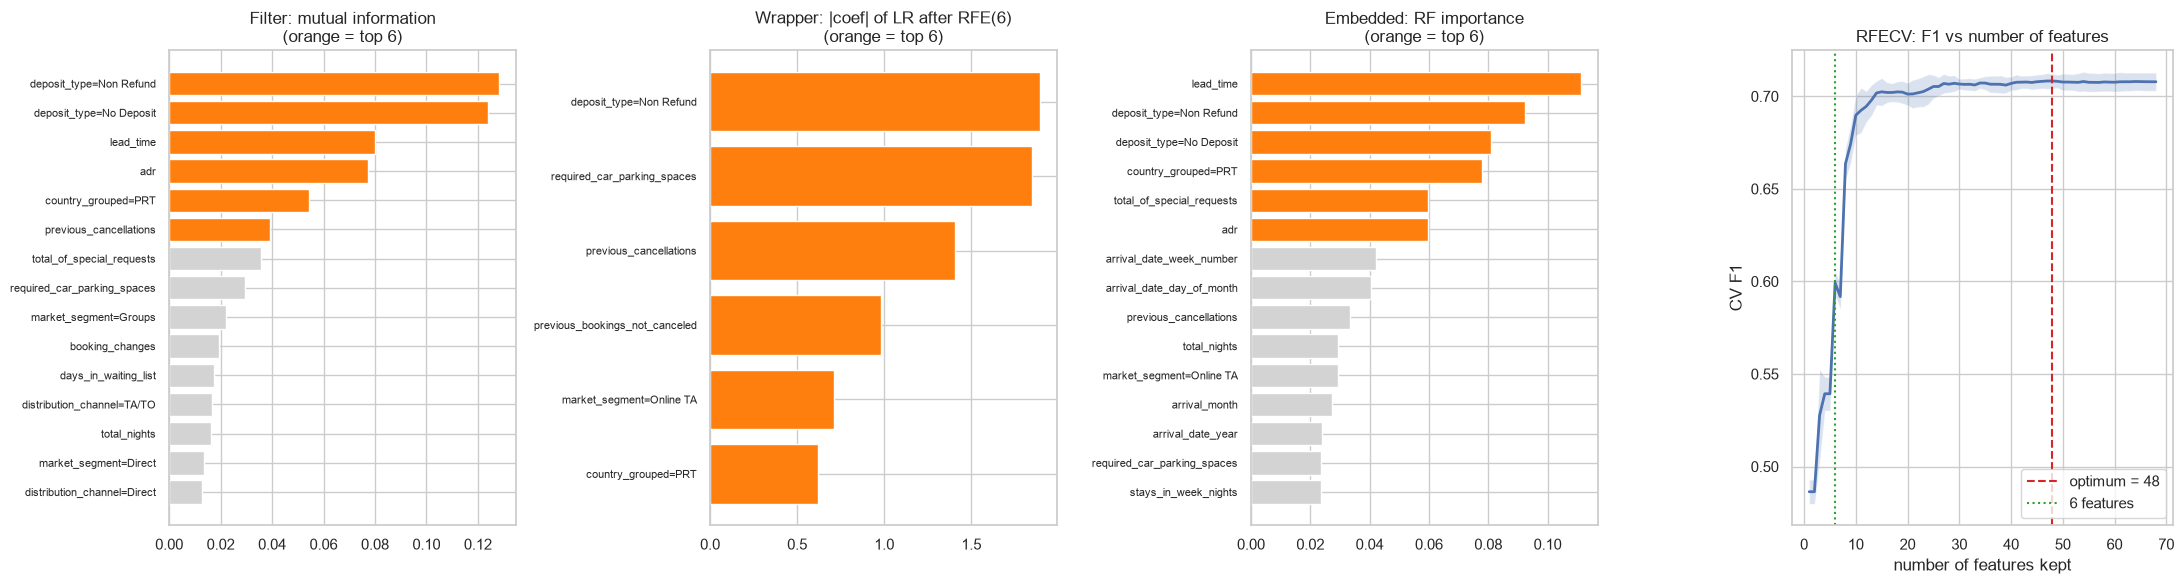

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(22, 6), gridspec_kw={'width_ratios': [1, 1, 1, 1.1]})
for ax, (title, scores, chosen) in zip(axes[:3], [
        ('Filter: mutual information', mi_scores, selected_sets['Filter (mutual information)']),
        ('Wrapper: |coef| of LR after RFE(6)', rfe6_coefs, selected_sets['Wrapper (RFE / logistic reg.)']),
        ('Embedded: RF importance', rf_importance, selected_sets['Embedded (RF importance)'])]):
    top = scores.head(15)[::-1]
    ax.barh(top.index, top.values, color=['tab:orange' if f in chosen else 'lightgray' for f in top.index])
    ax.set_title(title + '\n(orange = top 6)')
    ax.tick_params(axis='y', labelsize=8)
n_feats = rfecv.cv_results_.get('n_features', np.arange(1, len(rfecv.cv_results_['mean_test_score']) + 1))
mean_s, std_s = rfecv.cv_results_['mean_test_score'], rfecv.cv_results_['std_test_score']
axes[3].plot(n_feats, mean_s, lw=2)
axes[3].fill_between(n_feats, mean_s - std_s, mean_s + std_s, alpha=0.2)
axes[3].axvline(rfecv.n_features_, color='tab:red', ls='--', label=f'optimum = {rfecv.n_features_}')
axes[3].axvline(TOP_K, color='tab:green', ls=':', label='6 features')
axes[3].set_xlabel('number of features kept')
axes[3].set_ylabel('CV F1')
axes[3].set_title('RFECV: F1 vs number of features')
axes[3].legend()
plt.tight_layout()
plt.show()

**Interpretation 3.2.** **All three methods agree only on `deposit_type = Non Refund` and `country = PRT`**. Non-refundable deposits and Portuguese (domestic) bookings are well-known strong cancellation signals and are important both alone and together with other features. `lead_time`, `adr` and `deposit_type = No Deposit` are chosen by the filter and the embedded method but not by the wrapper, and `previous_cancellations` by the filter and the wrapper. **Selected by only one method:** `required_car_parking_spaces`, `previous_bookings_not_canceled`, `market_segment = Online TA` (wrapper) and `total_of_special_requests` (embedded).

The disagreement is expected because each method measures something different:
* **Mutual information** scores each feature *alone*, so it takes both `Non Refund` and `No Deposit` although together they contain almost the same information (one is nearly the complement of the other).
* **RFE with logistic regression** evaluates features *jointly and linearly*. It drops such redundancy, and it favours `required_car_parking_spaces` because almost no booking with a parking space is cancelled: a sharp effect gets a large coefficient. The non-monotonic effects of `lead_time` and `adr` fit a linear model poorly.
* **Random-Forest impurity importance** is biased toward continuous, high-cardinality features, so `lead_time`, `adr`, `arrival_date_week_number` and `arrival_date_day_of_month` rank high.

The RFECV curve adds an important nuance: F1 keeps rising until ~15 features and then stays on a plateau (optimum = 48), so **6 features are clearly fewer than the model needs**.

## Task 3.3 — Downstream impact of feature selection

Same model everywhere: `RandomForestClassifier(n_estimators=100, min_samples_leaf=2)`, 5-fold stratified CV on the **~89k rows not used for selection**. Feature sets: (a) all features, (b) all features minus the VIF-removed ones (Task 3.1), (c) wrapper top-6 (Task 3.2); (d) the RFECV-optimal subset is added for reference.

,n_features,accuracy,accuracy_std,F1,F1_std,ROC_AUC,fit_time_per_fold_s,total_cv_time_s
feature set,,,,,,,,
(a) All features,68,0.878,0.002,0.827,0.003,0.950,2.134,11.613
(b) VIF-reduced,66,0.877,0.002,0.825,0.003,0.949,1.852,10.047
(c) Wrapper top-6 (RFE),6,0.769,0.001,0.550,0.002,0.826,0.391,2.385
(d) RFECV optimum,48,0.876,0.002,0.823,0.003,0.949,1.580,8.668


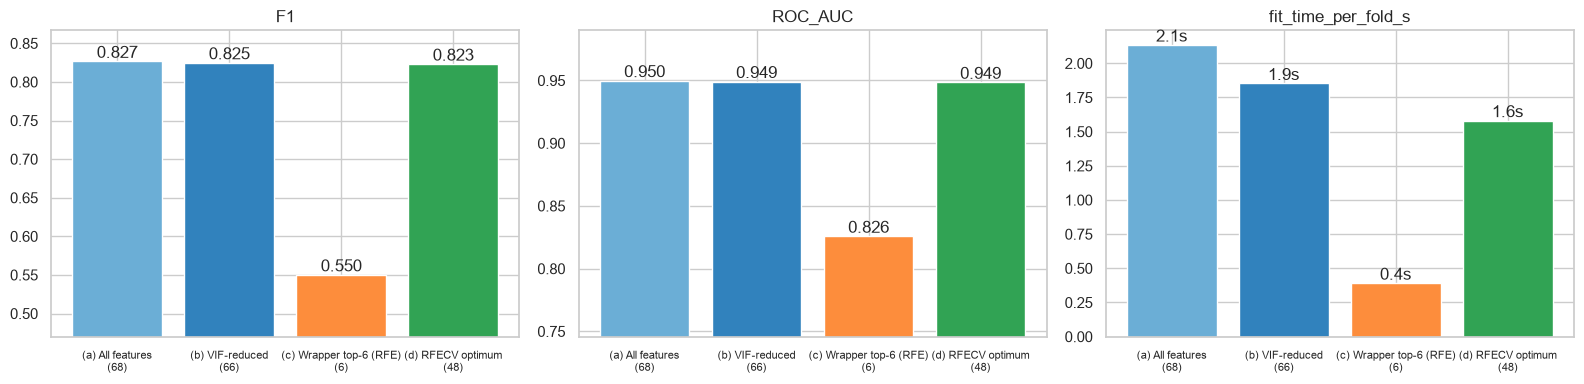

In [26]:
feature_sets = {
    '(a) All features': list(X_all.columns),
    '(b) VIF-reduced': [c for c in X_all.columns if c not in removed_features],
    '(c) Wrapper top-6 (RFE)': selected_sets['Wrapper (RFE / logistic reg.)'],
    '(d) RFECV optimum': list(X_sel.columns[rfecv.support_]),
}
rf_eval = RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=SEED)

rows = []
for name, cols in feature_sets.items():
    t0 = time.perf_counter()
    res = cross_validate(rf_eval, X_rest[cols], y_rest, cv=cv5, scoring=['accuracy', 'f1', 'roc_auc'])
    rows.append({'feature set': name, 'n_features': len(cols),
                 'accuracy': res['test_accuracy'].mean(), 'accuracy_std': res['test_accuracy'].std(),
                 'F1': res['test_f1'].mean(), 'F1_std': res['test_f1'].std(),
                 'ROC_AUC': res['test_roc_auc'].mean(),
                 'fit_time_per_fold_s': res['fit_time'].mean(), 'total_cv_time_s': time.perf_counter() - t0})
fs_results = pd.DataFrame(rows).set_index('feature set')
display(fs_results.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
colors = ['#6baed6', '#3182bd', '#fd8d3c', '#31a354']
for ax, metric in zip(axes, ['F1', 'ROC_AUC', 'fit_time_per_fold_s']):
    ax.bar(range(len(fs_results)), fs_results[metric], color=colors)
    ax.set_xticks(range(len(fs_results)), [f'{i}\n({n})' for i, n in zip(fs_results.index, fs_results['n_features'])],
                  fontsize=8)
    for i, v in enumerate(fs_results[metric]):
        ax.text(i, v, f'{v:.3f}' if metric != 'fit_time_per_fold_s' else f'{v:.1f}s', ha='center', va='bottom')
    ax.set_title(metric)
    if metric != 'fit_time_per_fold_s':
        ax.set_ylim(fs_results[metric].min() - 0.08, min(1, fs_results[metric].max() + 0.04))
plt.tight_layout()
plt.show()

**Interpretation 3.3.** **(a) All 68 features:** F1 = 0.827, ROC AUC = 0.950, ≈ 2.0 s per fold. **(b) VIF-reduced set:** removing `total_nights` and `arrival_date_week_number` costs nothing (F1 0.825, AUC 0.949, ≈ 1.9 s). This is expected, because tree ensembles are not harmed by collinearity; VIF matters for the stability and interpretability of *linear* models, not for random-forest accuracy. **(c) Wrapper top-6:** training is ≈ 5× faster (≈ 0.4 s per fold), but quality collapses: F1 0.550 (−0.277) and AUC 0.826 (−0.124), with accuracy 0.769 only ~14 pp above the majority baseline of 0.629. **(d) RFECV optimum (48 features):** results equal the full set within one standard deviation (F1 0.823 ± 0.003) with 20 fewer features and somewhat less training time (≈ 1.6–1.8 s vs ≈ 2.0 s per fold; timings vary slightly between runs). Conclusion: feature selection pays off when the subset size is chosen by cross-validation. A fixed "top 6" is a good way to *interpret* which features matter, but not a good way to build the model.

---
# Part 4. Feature Creation

## Task 4.1 — Engineered features from several attributes

In [27]:
def add_engineered_features(data):
    out = data.copy()
    total_nights = out['stays_in_weekend_nights'] + out['stays_in_week_nights']
    paying_guests = (out['adults'] + out['children']).clip(lower=1)
    prev_total = out['previous_cancellations'] + out['previous_bookings_not_canceled']

    # 1) price per paying guest per night = adr / (adults + children)
    out['adr_per_guest'] = out['adr'] / paying_guests
    # 2) personal cancellation rate = previous_cancellations / all previous bookings (0 if no history)
    out['cancel_history_rate'] = np.where(prev_total > 0, out['previous_cancellations'] / prev_total.clip(lower=1), 0.0)
    # 3) share of the stay that falls on weekend nights
    out['weekend_share'] = np.where(total_nights > 0, out['stays_in_weekend_nights'] / total_nights.clip(lower=1), 0.0)
    # 4) total value of the booking = price per night x number of nights
    out['booking_value'] = out['adr'] * total_nights
    return out


ENGINEERED = ['adr_per_guest', 'cancel_history_rate', 'weekend_share', 'booking_value']
COMPONENTS = {'adr_per_guest': ['adr', 'adults', 'children'],
              'cancel_history_rate': ['previous_cancellations', 'previous_bookings_not_canceled'],
              'weekend_share': ['stays_in_weekend_nights', 'stays_in_week_nights'],
              'booking_value': ['adr', 'total_nights']}
df = add_engineered_features(df)
display(df[ENGINEERED].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
adr_per_guest,"119,208.000",55.104,28.045,0.000,37.500,49.500,66.000,510.000
cancel_history_rate,"119,208.000",0.050,0.217,0.000,0.000,0.000,0.000,1.000
weekend_share,"119,208.000",0.253,0.281,0.000,0.000,0.250,0.400,1.000
booking_value,"119,208.000",358.271,335.589,0.000,146.700,267.000,446.670,"7,590.000"


,MI(new feature),components,max MI of a single component,gain vs best component
engineered feature,,,,
adr_per_guest,0.069,"adr=0.0720, adults=0.0038, children=0.0005",0.072,-0.004
cancel_history_rate,0.046,"previous_cancellations=0.0393, previous_bookin...",0.039,0.007
weekend_share,0.004,"stays_in_weekend_nights=0.0005, stays_in_week_...",0.001,0.003
booking_value,0.079,"adr=0.0739, total_nights=0.0102",0.074,0.006


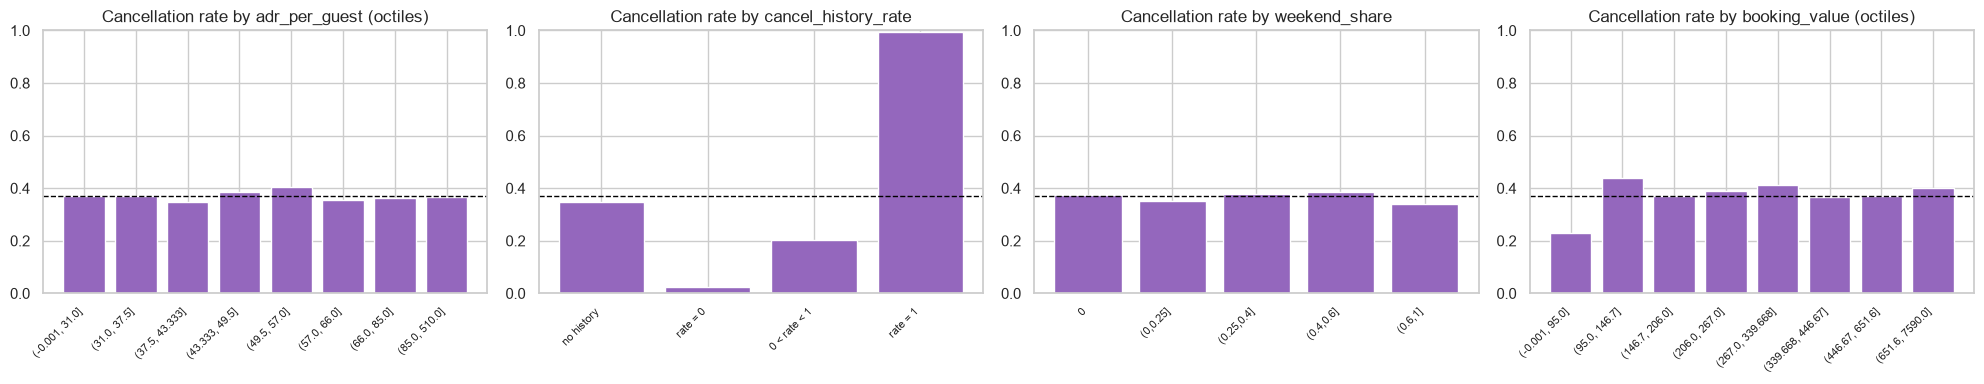

In [28]:
# Evidence: mutual information with the target of each new feature vs. its raw components (same 30k stratified rows)
mi_rows = []
eval_idx = X_sel.index
for feat, comps in COMPONENTS.items():
    cols = [feat] + comps
    Xm = df.loc[eval_idx, cols]
    mi_vals = mutual_info_classif(Xm, df.loc[eval_idx, TARGET], discrete_features=(Xm.nunique() <= 20).to_numpy(),
                                  random_state=SEED)
    mi_rows.append({'engineered feature': feat, 'MI(new feature)': mi_vals[0],
                    'components': ', '.join(f'{c}={v:.4f}' for c, v in zip(comps, mi_vals[1:])),
                    'max MI of a single component': mi_vals[1:].max(),
                    'gain vs best component': mi_vals[0] - mi_vals[1:].max()})
display(pd.DataFrame(mi_rows).set_index('engineered feature').round(4))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
tmp = df[ENGINEERED + [TARGET, 'previous_cancellations', 'previous_bookings_not_canceled']].copy()
tmp['adr_per_guest_bin'] = pd.qcut(tmp['adr_per_guest'], 8, duplicates='drop')
tmp['booking_value_bin'] = pd.qcut(tmp['booking_value'], 8, duplicates='drop')
tmp['weekend_share_bin'] = pd.cut(tmp['weekend_share'], [-0.01, 0, 0.25, 0.4, 0.6, 1.0],
                                  labels=['0', '(0,0.25]', '(0.25,0.4]', '(0.4,0.6]', '(0.6,1]'])
prev_total = tmp['previous_cancellations'] + tmp['previous_bookings_not_canceled']
tmp['history_bin'] = np.select([prev_total == 0, tmp['cancel_history_rate'] == 0,
                                tmp['cancel_history_rate'] < 1], ['no history', 'rate = 0', '0 < rate < 1'], 'rate = 1')
for ax, col, title in zip(axes, ['adr_per_guest_bin', 'history_bin', 'weekend_share_bin', 'booking_value_bin'],
                          ['adr_per_guest (octiles)', 'cancel_history_rate', 'weekend_share', 'booking_value (octiles)']):
    rate = tmp.groupby(col, observed=True)[TARGET].agg(['mean', 'size'])
    if col == 'history_bin':
        rate = rate.reindex(['no history', 'rate = 0', '0 < rate < 1', 'rate = 1'])
    ax.bar(range(len(rate)), rate['mean'], color='tab:purple')
    ax.set_xticks(range(len(rate)), [str(i) for i in rate.index], rotation=45, ha='right', fontsize=8)
    ax.axhline(df[TARGET].mean(), color='black', ls='--', lw=1)
    ax.set_title(f'Cancellation rate by {title}')
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Why each feature captures information the raw attributes do not individually.**

| Feature | Formula | What it adds | Evidence from the output |
|---|---|---|---|
| `cancel_history_rate` | previous_cancellations / (previous_cancellations + previous_bookings_not_canceled) | The raw counts cannot tell "1 cancellation out of 1 booking" from "1 out of 20". The rate measures the guest's *reliability* independent of how often they booked. | MI 0.046 vs 0.039 for the best component (+18%). Guests with rate = 1 cancel ≈ 99% of the time, with rate = 0 almost never. In Task 4.4 it is the 7th most important feature. |
| `booking_value` | adr × total_nights | The money at stake. A cheap long stay and an expensive short stay can have the same value, which neither `adr` nor the number of nights shows alone. | MI 0.079 vs 0.074 for `adr` (+0.006). The cheapest octile (≤ 95) cancels only ≈ 23% vs the 37% average. |
| `weekend_share` | weekend_nights / total_nights | Describes the *type* of trip (leisure weekend vs business week) independent of its length; the raw night counts mix type and duration. | MI rises from 0.001 to 0.004. It is still a weak signal: cancellation rate varies only ≈ 34–39% across bins. |
| `adr_per_guest` | adr / (adults + children) | Price per person rather than per room: an ADR of 200 means something different for 1 guest than for 4. | MI 0.069 vs 0.072 for `adr`, so **no gain** for predicting cancellations: here room price already carries the signal. The feature is kept because it is meaningful for pricing analysis, but this result is reported honestly. |

Overall, the ratio features help when the *ratio* itself is what matters for behaviour (`cancel_history_rate`). They help much less when the model can already see the underlying column (`adr_per_guest`).

## Task 4.2 — Date decomposition and cyclical encoding

The arrival date (built from `arrival_date_year`, `arrival_date_month`, `arrival_date_day_of_month`) is decomposed into year, month, day-of-week and is_weekend. Month (period 12) and day-of-week (period 7) are then mapped onto the unit circle:
$\;x_{\sin} = \sin(2\pi \cdot v / P),\; x_{\cos} = \cos(2\pi \cdot v / P)$.

In [29]:
def add_date_features(data):
    out = data.copy()
    month = out['arrival_date_month'].map({m: i for i, m in enumerate(MONTHS, start=1)})
    date = pd.to_datetime(pd.DataFrame({'year': out['arrival_date_year'], 'month': month,
                                        'day': out['arrival_date_day_of_month']}))
    out['arrival_year'] = date.dt.year
    out['arrival_month'] = month
    out['arrival_dow'] = date.dt.dayofweek                    # Monday = 0 ... Sunday = 6
    out['arrival_is_weekend'] = (out['arrival_dow'] >= 5).astype(int)
    out['month_sin'] = np.sin(2 * np.pi * out['arrival_month'] / 12)
    out['month_cos'] = np.cos(2 * np.pi * out['arrival_month'] / 12)
    out['dow_sin'] = np.sin(2 * np.pi * out['arrival_dow'] / 7)
    out['dow_cos'] = np.cos(2 * np.pi * out['arrival_dow'] / 7)
    return out


DATE_FEATURES = ['arrival_year', 'arrival_month', 'arrival_dow', 'arrival_is_weekend',
                 'month_sin', 'month_cos', 'dow_sin', 'dow_cos']
df = add_date_features(df)
example = df[['arrival_date'] + DATE_FEATURES].drop_duplicates('arrival_month').sort_values('arrival_month')
display(example.round({c: 3 for c in DATE_FEATURES}))

,arrival_date,arrival_year,arrival_month,arrival_dow,arrival_is_weekend,month_sin,month_cos,dow_sin,dow_cos
3733,2016-01-01,2016,1,4,0,0.500,0.866,-0.434,-0.901
3859,2016-02-01,2016,2,0,0,0.866,0.500,0.000,1.000
4269,2016-03-01,2016,3,1,0,1.000,0.000,0.782,0.623
4797,2016-04-01,2016,4,4,0,0.866,-0.500,-0.434,-0.901
5515,2016-05-01,2016,5,6,1,0.500,-0.866,-0.782,0.623
6269,2016-06-01,2016,6,2,0,0.000,-1.000,0.975,-0.223
0,2015-07-01,2015,7,2,0,-0.500,-0.866,0.975,-0.223
842,2015-08-01,2015,8,5,1,-0.866,-0.500,-0.975,-0.223
1485,2015-09-01,2015,9,1,0,-1.000,-0.000,0.782,0.623
2087,2015-10-01,2015,10,3,0,-0.866,0.500,0.434,-0.901


,raw |month difference|,cyclic Euclidean distance
pair,,
December - January,11,0.518
January - June,5,1.932
June - July,1,0.518
November - February,9,1.414


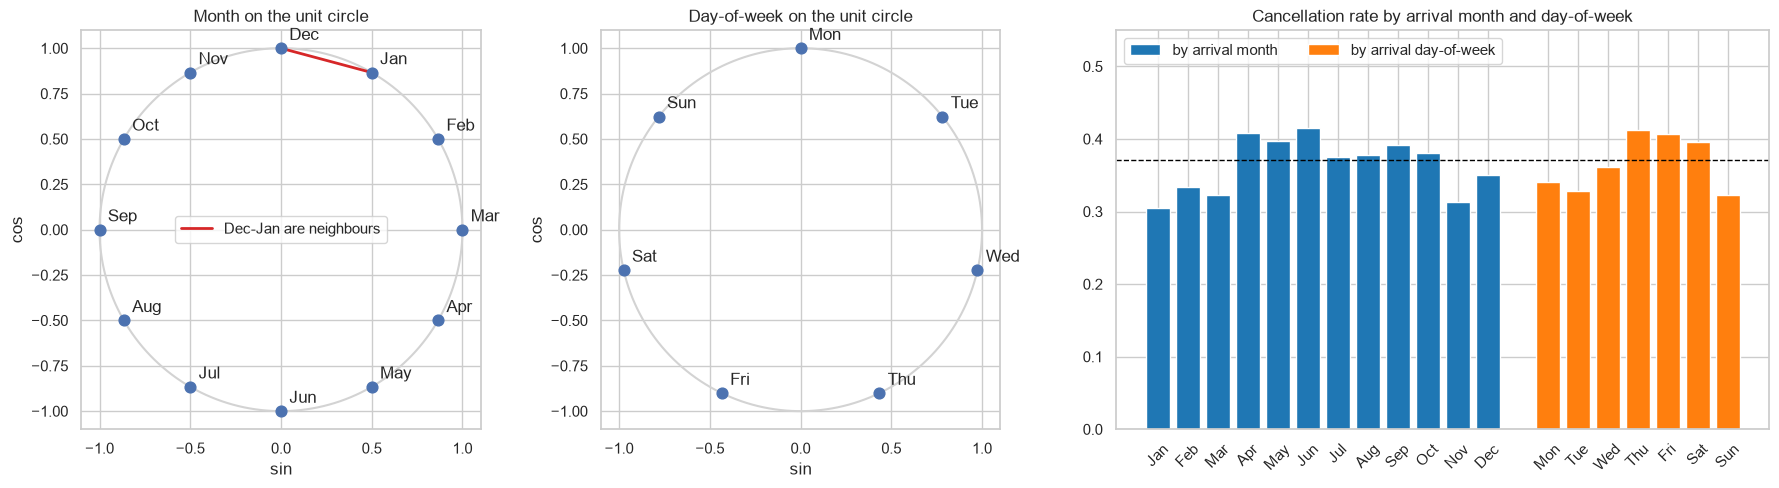

In [30]:
def cyc(v, period):
    return np.array([np.sin(2 * np.pi * v / period), np.cos(2 * np.pi * v / period)])


pairs = [('December', 12, 'January', 1), ('January', 1, 'June', 6), ('June', 6, 'July', 7), ('November', 11, 'February', 2)]
display(pd.DataFrame([{'pair': f'{a} - {b}', 'raw |month difference|': abs(va - vb),
                       'cyclic Euclidean distance': np.linalg.norm(cyc(va, 12) - cyc(vb, 12))}
                      for a, va, b, vb in pairs]).set_index('pair').round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1, 1.6]})
theta = np.linspace(0, 2 * np.pi, 200)
for ax, period, names, title in [(axes[0], 12, [m[:3] for m in MONTHS], 'Month on the unit circle'),
                                 (axes[1], 7, ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], 'Day-of-week on the unit circle')]:
    ax.plot(np.sin(theta), np.cos(theta), color='lightgray')
    values = np.arange(1, 13) if period == 12 else np.arange(0, 7)
    pts = np.array([cyc(v, period) for v in values])
    ax.scatter(pts[:, 0], pts[:, 1], s=60, zorder=3)
    for (sx, cx), name in zip(pts, names):
        ax.annotate(name, (sx, cx), textcoords='offset points', xytext=(6, 6))
    if period == 12:
        dec, jan = cyc(12, 12), cyc(1, 12)
        ax.plot([dec[0], jan[0]], [dec[1], jan[1]], color='tab:red', lw=2, label='Dec-Jan are neighbours')
        ax.legend(loc='center')
    ax.set_aspect('equal')
    ax.set_xlabel('sin')
    ax.set_ylabel('cos')
    ax.set_title(title)

month_rate = df.groupby('arrival_month')[TARGET].mean()
dow_rate = df.groupby('arrival_dow')[TARGET].mean()
axes[2].bar(np.arange(12), month_rate.values, color='tab:blue', label='by arrival month')
axes[2].bar(np.arange(13, 20), dow_rate.values, color='tab:orange', label='by arrival day-of-week')
axes[2].set_xticks(list(range(12)) + list(range(13, 20)),
                   [m[:3] for m in MONTHS] + ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], rotation=45)
axes[2].axhline(df[TARGET].mean(), color='black', ls='--', lw=1)
axes[2].set_title('Cancellation rate by arrival month and day-of-week')
axes[2].set_ylim(0, 0.55)
axes[2].legend(loc='upper left', ncol=2)
plt.tight_layout()
plt.show()

**Interpretation 4.2.** With raw month numbers, December (12) and January (1) are 11 units apart, the maximum possible distance. After sin/cos encoding **their distance is 0.518, exactly the same as June–July**, while opposite months such as January–June are 1.932 apart (the maximum is 2). This matters for this dataset because cancellation behaviour really is cyclic. The lowest cancellation rates are in the winter block **Nov (≈ 0.31), Dec (≈ 0.35), Jan (≈ 0.30)**, and the highest in spring/summer (Apr ≈ 0.41, Jun ≈ 0.41). With the raw month a linear model has to treat 11, 12 and 1 as far apart, and a tree has to spend two splits to join them; on the circle they form one region. Day-of-week follows the same logic: arrivals on Thu–Sat cancel more often (≈ 0.40) than on Sun–Tue (≈ 0.32–0.34). Both sin and cos are needed: with sin alone, different months collide (February and April both get 0.866).

## Task 4.3 — Feature extraction with PCA

In [31]:
# total_nights is excluded: it is an exact sum of two other columns and would only add a zero-variance component
pca_features = [c for c in numeric_candidates if c != 'total_nights']
X_num = df[pca_features].astype(float)
Z = StandardScaler().fit_transform(X_num)
pca_full = PCA(random_state=SEED).fit(Z)

evr = pd.DataFrame({'eigenvalue': pca_full.explained_variance_,
                    'explained_variance_ratio': pca_full.explained_variance_ratio_,
                    'cumulative': np.cumsum(pca_full.explained_variance_ratio_)},
                   index=[f'PC{i + 1}' for i in range(len(pca_features))])
k90 = int(np.argmax(evr['cumulative'].to_numpy() >= 0.90) + 1)
print(f'{len(pca_features)} standardized numeric features -> minimum number of components for >= 90% variance: k = {k90} '
      f'({evr["cumulative"].iloc[k90 - 1]:.2%})')
display(evr.style.format({'eigenvalue': '{:.3f}', 'explained_variance_ratio': '{:.2%}', 'cumulative': '{:.2%}'})
        .apply(lambda r: ['background-color: #fde0dd' if r.name == f'PC{k90}' else '' for _ in r], axis=1))

20 standardized numeric features -> minimum number of components for >= 90% variance: k = 15 (90.83%)


,eigenvalue,explained_variance_ratio,cumulative
PC1,2.541,12.71%,12.71%
PC2,2.363,11.81%,24.52%
PC3,1.605,8.02%,32.54%
PC4,1.448,7.24%,39.78%
PC5,1.182,5.91%,45.69%
PC6,1.102,5.51%,51.20%
PC7,1.061,5.31%,56.51%
PC8,0.997,4.98%,61.49%
PC9,0.952,4.76%,66.25%
PC10,0.937,4.69%,70.94%


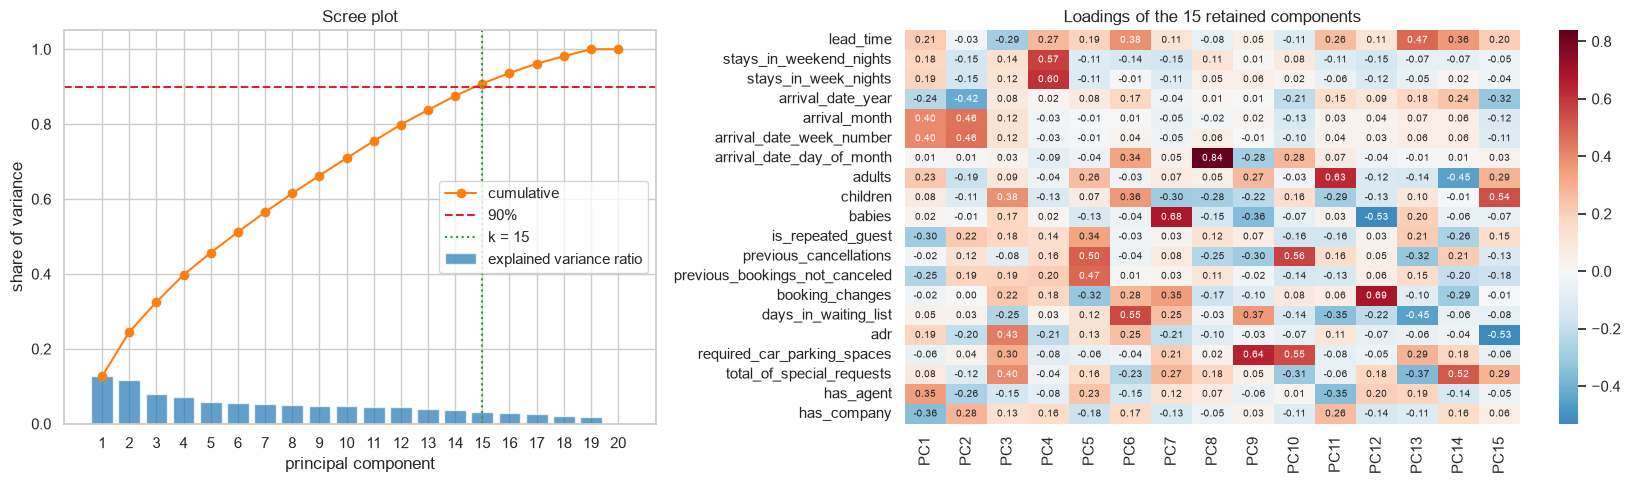

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={'width_ratios': [1, 1.3]})
idx = np.arange(1, len(evr) + 1)
axes[0].bar(idx, evr['explained_variance_ratio'], color='tab:blue', alpha=0.7, label='explained variance ratio')
axes[0].plot(idx, evr['cumulative'], 'o-', color='tab:orange', label='cumulative')
axes[0].axhline(0.90, color='tab:red', ls='--', label='90%')
axes[0].axvline(k90, color='tab:green', ls=':', label=f'k = {k90}')
axes[0].set_xticks(idx)
axes[0].set_xlabel('principal component')
axes[0].set_ylabel('share of variance')
axes[0].set_title('Scree plot')
axes[0].legend(loc='center right')

loadings = pd.DataFrame(pca_full.components_[:k90].T, index=pca_features, columns=[f'PC{i + 1}' for i in range(k90)])
sns.heatmap(loadings, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=axes[1])
axes[1].set_title(f'Loadings of the {k90} retained components')
plt.tight_layout()
plt.show()

In [33]:
simple_models = {
    '(a) Original numeric features': Pipeline([('scale', StandardScaler()),
                                               ('lr', LogisticRegression(max_iter=3000))]),
    f'(b) PCA components (k={k90})': Pipeline([('scale', StandardScaler()), ('pca', PCA(n_components=k90, random_state=SEED)),
                                               ('lr', LogisticRegression(max_iter=3000))]),
}
rows = []
for name, model in simple_models.items():
    res = cross_validate(model, X_num, y_all, cv=cv5, scoring=['accuracy', 'f1', 'roc_auc'])
    rows.append({'model': name, 'n_inputs': len(pca_features) if name.startswith('(a)') else k90,
                 'accuracy': res['test_accuracy'].mean(), 'F1': res['test_f1'].mean(),
                 'ROC_AUC': res['test_roc_auc'].mean(), 'fit_time_per_fold_s': res['fit_time'].mean()})
pca_results = pd.DataFrame(rows).set_index('model')
display(pca_results.round(4))

# How is the most "behavioural" information spread over the components?
scores = pca_full.transform(Z)[:, :k90]
corr_hist = pd.Series([np.corrcoef(scores[:, i], df['cancel_history_rate'])[0, 1] for i in range(k90)],
                      index=[f'PC{i + 1}' for i in range(k90)])
print('Correlation of engineered cancel_history_rate with each retained PC:')
print(corr_hist.round(3).to_dict())
print(f'max |corr| = {corr_hist.abs().max():.3f}; corr(cancel_history_rate, previous_cancellations) = '
      f'{np.corrcoef(df["cancel_history_rate"], df["previous_cancellations"])[0, 1]:.3f}')

,n_inputs,accuracy,F1,ROC_AUC,fit_time_per_fold_s
model,,,,,
(a) Original numeric features,20,0.737,0.585,0.795,0.146
(b) PCA components (k=15),15,0.732,0.580,0.788,0.119


Correlation of engineered cancel_history_rate with each retained PC:
{'PC1': 0.078, 'PC2': 0.204, 'PC3': -0.213, 'PC4': 0.081, 'PC5': 0.238, 'PC6': 0.0, 'PC7': 0.047, 'PC8': -0.111, 'PC9': -0.12, 'PC10': 0.231, 'PC11': 0.063, 'PC12': 0.003, 'PC13': -0.01, 'PC14': 0.048, 'PC15': 0.091}
max |corr| = 0.238; corr(cancel_history_rate, previous_cancellations) = 0.406


**Interpretation 4.3.** **PCA needs 15 of the 20 standardized numeric features to retain ≥ 90% of the variance (90.83%).** PC1 explains only 12.7% and PC2 11.8%, and just 7 components have eigenvalue > 1. The scree plot has no clear "elbow", which agrees with Task 3.1: after the two collinear pairs, the features are nearly uncorrelated (VIF ≈ 1–1.7), so there is no redundant variance to compress. PC20 has ≈ 0 variance because week number is almost a function of month. As a result the logistic regression gains almost nothing: accuracy 0.737 → 0.732, F1 0.585 → 0.580, ROC AUC 0.795 → 0.788, with fit time only marginally lower (≈ 0.13 → 0.12 s per fold, because only 5 inputs were removed).

**Downside for this dataset:** PCA is unsupervised and linear. It keeps directions of large *variance*, not of predictive power, and it cannot build ratios. The strongest behavioural signal, the guest's cancellation history, is rare and low-variance, so PCA smears it across several components: `previous_cancellations` loads 0.50 on PC5 (mixed with `is_repeated_guest` and `previous_bookings_not_canceled`) and 0.56 on PC10 (mixed with `required_car_parking_spaces`). The engineered `cancel_history_rate` from Task 4.1 correlates at most **|r| = 0.24** with any retained component. A hotel manager can act on "this guest cancelled 100% of previous bookings", but not on "PC10 is high".

## Task 4.4 — End-to-end preprocessing pipeline

The pipeline receives the **cleaned raw columns** only and does everything else inside `fit`/`transform`, so every learned statistic is computed on the training fold only (no leakage in cross-validation):

1. `DateFeatures` — Task 4.2 (decomposition + sin/cos encoding).
2. `EngineeredFeatures` — Task 4.1 (ratios / interactions).
3. `GroupAggregateFeatures` — Tasks 1.1–1.2: learns the **nights-weighted mean ADR** per (`hotel`, `market_segment`) and per (`hotel`, arrival month) on the training data and adds how expensive a booking is relative to its group; groups with n < 30 (Task 1.1b) fall back to the hotel-level weighted mean.
4. `ColumnTransformer` — keeps the **selected feature subset** (Task 3.1 VIF-reduced numeric features ∩ RFECV-selected source columns from Task 3.2) plus the new features; imputes numeric columns and one-hot-encodes categoricals (rare categories grouped).
5. Model — `HistGradientBoostingClassifier`.

Sampling (Task 2.2): **stratified** 80/20 train/test split and `StratifiedKFold` CV.

In [34]:
class DateFeatures(BaseEstimator, TransformerMixin):
    """Task 4.2: arrival-date decomposition + cyclical encoding."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return add_date_features(X)


class EngineeredFeatures(BaseEstimator, TransformerMixin):
    """Task 4.1: features combining several raw attributes."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        out = add_engineered_features(X)
        out['total_nights'] = out['stays_in_weekend_nights'] + out['stays_in_week_nights']
        return out


class GroupAggregateFeatures(BaseEstimator, TransformerMixin):
    """Tasks 1.1-1.2: nights-weighted mean ADR per group, learned on the training data only."""
    def __init__(self, min_group_size=30):
        self.min_group_size = min_group_size

    @staticmethod
    def _weighted_adr(data, keys):
        nights = data['stays_in_weekend_nights'] + data['stays_in_week_nights']
        tmp = data.assign(_w=nights, _wx=nights * data['adr'])
        g = tmp.groupby(keys).agg(_wx=('_wx', 'sum'), _w=('_w', 'sum'), n=('adr', 'size'))
        g['wmean'] = g['_wx'] / g['_w'].where(g['_w'] > 0)       # x̄_w = Σ w·x / Σ w
        return g[['wmean', 'n']]

    def fit(self, X, y=None):
        X = add_date_features(X) if 'arrival_month' not in X else X
        self.hotel_ = self._weighted_adr(X, ['hotel'])['wmean']
        self.segment_ = self._weighted_adr(X, ['hotel', 'market_segment'])
        self.month_ = self._weighted_adr(X, ['hotel', 'arrival_month'])
        return self

    def _lookup(self, X, table, keys):
        idx = pd.MultiIndex.from_frame(X[keys])
        stats_ = table.reindex(idx)
        fallback = self.hotel_.reindex(X['hotel']).to_numpy()
        small = (stats_['n'].fillna(0) < self.min_group_size).to_numpy() | stats_['wmean'].isna().to_numpy()
        return np.where(small, fallback, stats_['wmean'].to_numpy()), small

    def transform(self, X):
        out = X.copy()
        seg_mean, seg_small = self._lookup(out, self.segment_, ['hotel', 'market_segment'])
        month_mean, _ = self._lookup(out, self.month_, ['hotel', 'arrival_month'])
        out['segment_wmean_adr'] = seg_mean
        out['adr_vs_segment'] = out['adr'] / seg_mean
        out['adr_vs_month'] = out['adr'] / month_mean
        out['segment_is_small'] = seg_small.astype(int)
        return out


# ---- Feature subset coming from Part 3 ----------------------------------------------------------------------
source_of = lambda feature: feature.split('=')[0]
rfecv_sources = {source_of(f) for f in X_sel.columns[rfecv.support_]}
pipe_numeric = [c for c in vif_numeric_kept if c in rfecv_sources and c not in ('arrival_month',)]
pipe_categorical = [('country' if c == 'country_grouped' else c) for c in categorical_features if c in rfecv_sources]
new_numeric = ENGINEERED + ['month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'arrival_is_weekend',
                            'segment_wmean_adr', 'adr_vs_segment', 'adr_vs_month', 'segment_is_small']
print('Selected raw numeric features :', pipe_numeric)
print('Selected raw categorical      :', pipe_categorical)
print('Added (engineered/date/aggregation):', new_numeric)

input_columns = [c for c in raw.columns if c in df.columns] + ['has_agent', 'has_company']
X_raw = df[input_columns]
X_train, X_test, y_train, y_test = train_test_split(X_raw, y_all, test_size=0.2, stratify=y_all, random_state=SEED)

final_pipeline = Pipeline([
    ('dates', DateFeatures()),                                    # Task 4.2
    ('engineered', EngineeredFeatures()),                         # Task 4.1
    ('group_agg', GroupAggregateFeatures(min_group_size=MIN_N)),  # Tasks 1.1-1.2
    ('preprocess', ColumnTransformer([                            # Task 3.1 / 3.2 subset
        ('num', SimpleImputer(strategy='median'), pipe_numeric + new_numeric),
        # max_categories=11 -> top-10 categories + "infrequent", the same country grouping as in Part 3
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', max_categories=11, sparse_output=False),
         pipe_categorical),
    ], remainder='drop')),
    ('model', HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED)),
])
final_pipeline

Selected raw numeric features : ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'arrival_date_year', 'adults', 'children', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'has_company']
Selected raw categorical      : ['hotel', 'meal', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type', 'reserved_room_type', 'country']
Added (engineered/date/aggregation): ['adr_per_guest', 'cancel_history_rate', 'weekend_share', 'booking_value', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'arrival_is_weekend', 'segment_wmean_adr', 'adr_vs_segment', 'adr_vs_month', 'segment_is_small']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dates', ...), ('engineered', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,min_group_size,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: fl

In [35]:
t0 = time.perf_counter()
cv_res = cross_validate(final_pipeline, X_train, y_train, cv=cv5, scoring=['accuracy', 'f1', 'roc_auc'])
print(f'5-fold stratified CV on the training set ({len(X_train):,} rows) in {time.perf_counter() - t0:.1f}s')
print({m: f"{cv_res['test_' + m].mean():.4f} ± {cv_res['test_' + m].std():.4f}" for m in ['accuracy', 'f1', 'roc_auc']})

t0 = time.perf_counter()
final_pipeline.fit(X_train, y_train)
train_time = time.perf_counter() - t0
proba = final_pipeline.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
n_model_features = len(final_pipeline.named_steps['preprocess'].get_feature_names_out())

# Reference: the same model on the plain one-hot matrix from Part 3 (no engineered / aggregation features)
baseline = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED)
t0 = time.perf_counter()
baseline.fit(X_all.loc[X_train.index], y_train)
base_time = time.perf_counter() - t0
base_proba = baseline.predict_proba(X_all.loc[X_test.index])[:, 1]

final_tbl = pd.DataFrame([
    {'model': 'Final pipeline (selected + engineered + aggregation features)', 'n_features': n_model_features,
     'test_accuracy': accuracy_score(y_test, pred), 'test_F1': f1_score(y_test, pred),
     'test_ROC_AUC': roc_auc_score(y_test, proba), 'train_time_s': train_time},
    {'model': 'Reference: same model, all Part-3 features, no feature creation', 'n_features': X_all.shape[1],
     'test_accuracy': accuracy_score(y_test, (base_proba >= 0.5).astype(int)),
     'test_F1': f1_score(y_test, (base_proba >= 0.5).astype(int)),
     'test_ROC_AUC': roc_auc_score(y_test, base_proba), 'train_time_s': base_time},
]).set_index('model')
display(final_tbl.round(4))
print(classification_report(y_test, pred, target_names=['not cancelled', 'cancelled'], digits=3))

5-fold stratified CV on the training set (95,366 rows) in 28.7s
{'accuracy': '0.8715 ± 0.0028', 'f1': '0.8201 ± 0.0038', 'roc_auc': '0.9453 ± 0.0016'}


,n_features,test_accuracy,test_F1,test_ROC_AUC,train_time_s
model,,,,,
Final pipeline (selected + engineered + aggregation features),75,0.870,0.817,0.947,6.351
"Reference: same model, all Part-3 features, no feature creation",68,0.871,0.818,0.946,5.147


               precision    recall  f1-score   support

not cancelled      0.879     0.920     0.899     15002
    cancelled      0.853     0.785     0.817      8840

     accuracy                          0.870     23842
    macro avg      0.866     0.853     0.858     23842
 weighted avg      0.869     0.870     0.869     23842



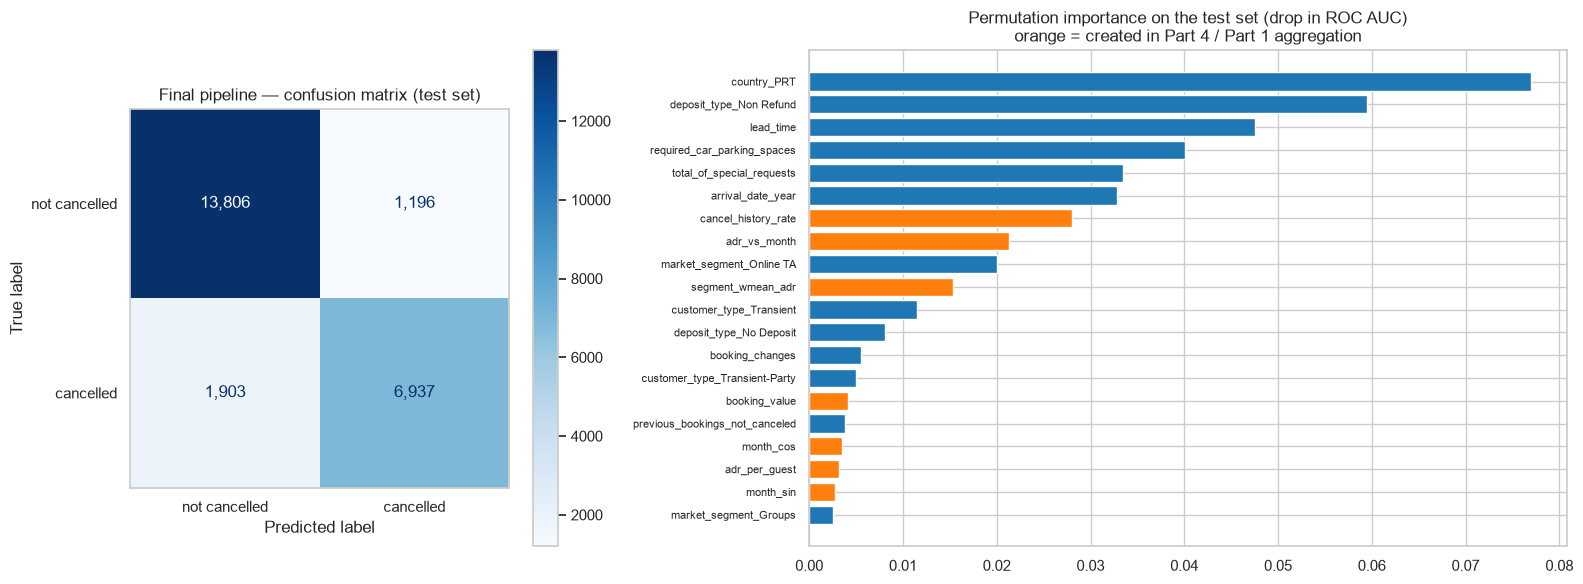

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.6]})
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['not cancelled', 'cancelled'],
                                        cmap='Blues', values_format=',', ax=axes[0])
axes[0].grid(False)
axes[0].set_title('Final pipeline — confusion matrix (test set)')

prefit = final_pipeline[:-1]
Xt_test = prefit.transform(X_test)
feat_names = [n.split('__', 1)[1] for n in final_pipeline.named_steps['preprocess'].get_feature_names_out()]
perm = permutation_importance(final_pipeline.named_steps['model'], Xt_test, y_test, scoring='roc_auc',
                              n_repeats=5, random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=feat_names).sort_values(ascending=False).head(20)[::-1]
axes[1].barh(perm_s.index, perm_s.values,
             color=['tab:orange' if f in new_numeric else 'tab:blue' for f in perm_s.index])
axes[1].set_title('Permutation importance on the test set (drop in ROC AUC)\norange = created in Part 4 / Part 1 aggregation')
axes[1].tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

**Final result.** On 5-fold stratified CV over the 95,366 training rows the pipeline reaches **accuracy 0.872 ± 0.003, F1 0.820 ± 0.004, ROC AUC 0.945 ± 0.002**. On the held-out test set of 23,842 bookings it reaches **accuracy 0.870, F1 0.817, ROC AUC 0.947**. Cancellations are detected with precision 0.853 and recall 0.785: 6,937 of 8,840 cancellations are found and 1,196 stays are falsely flagged. Three created features are among the ten most important by permutation importance: `cancel_history_rate` (Task 4.1), `adr_vs_month` and `segment_wmean_adr` (aggregation from Part 1). Still, the same boosting model on the plain Part-3 matrix scores essentially the same (F1 0.818, AUC 0.946). This difference is within the CV standard deviation: a gradient-boosting model can learn most interactions from the raw columns itself. The main value of the pipeline is therefore that it is **leakage-free and deployable**: it takes raw booking columns, and every group statistic is learned inside `fit` on the training fold only.

| Pipeline element | Comes from | Justification |
|---|---|---|
| Leakage columns removed before modelling | Section 0 | `reservation_status`, its date and `assigned_room_type` are only known after the outcome. |
| Stratified 80/20 split + `StratifiedKFold(5)` | Task 2.2 | Stratification gave KL = 2.4·10⁻¹⁰ vs 3.6·10⁻⁵ (random) and 0.21 (convenience); every fold keeps the 37.1% cancellation rate. |
| Train on the full training set, not a subsample | Task 2.3 | ~2.5k rows suffice to estimate a *mean* within 5%, but a classifier needs many more rows to learn rare patterns (e.g. `cancel_history_rate = 1`, n < 30 groups); training takes only ≈ 6 s. |
| `DateFeatures`: year/month/day-of-week/is_weekend + sin/cos | Task 4.2 | The low-cancellation winter block Nov–Jan is contiguous only on the circle. |
| `EngineeredFeatures` | Task 4.1 | `cancel_history_rate` adds +18% MI over its components and ranks 7th in permutation importance. |
| `GroupAggregateFeatures`: nights-weighted ADR per (hotel, segment) and (hotel, month) | Tasks 1.2, 1.1b, 1.3 | Weighted mean = true price per room-night (1.2). Groups with n < 30 fall back to the hotel-level value (1.1b). The month level is used because it still keeps 28% of ADR variance, while year keeps only 4% (1.3). Everything is fitted on training data only. |
| Numeric subset without `total_nights`, `arrival_date_week_number` | Task 3.1 | VIF ≈ 10¹⁵ and 1,160 (redundant). |
| Drop `babies`, `has_agent`, `arrival_date_day_of_month`, `arrival_month` (replaced by sin/cos) | Task 3.2 (RFECV) | RFECV kept 48 of 68 features with no loss of F1 (Task 3.3). A fixed top-6 was **not** used because it lost 0.28 F1. |
| No PCA | Task 4.3 | PCA reduced AUC 0.795 → 0.788 and destroyed interpretability. |
| `OneHotEncoder(max_categories=11)` | Part 3 preparation | Same "top-10 countries + other" grouping; unseen categories map to "infrequent" instead of crashing. |
| `HistGradientBoostingClassifier` | Tasks 3.2 / 4.1 | Key effects are non-linear (lead time, parking spaces, ratio features), and histogram boosting trains on 95k rows in seconds. |